# Инженерия признаков: прогнозирование покупки на сайте e-commerce

## 1. Титульный лист

**Дисциплина:** Машинное обучение и ИИ  
**Модуль 4:** Инженерия признаков и работа с нестандартными данными  
**Датасет:** Online Shoppers Purchasing Intention (UCI ML Repository, ID 468)

**Выполнила:** Емельянова Ксения Павловна  
**Группа:** ПКТб-23-1
**Преподаватель:** Спирин Игорь Сергеевич

**Ссылка на репозиторий:** https://github.com/fivifri/ml-course-emelyanova  
**Путь к модулю:** `module-4-features/notebook.ipynb`  
**Дата сдачи:** 2026-10-28

## 2. Введение

### 2.1. Какую задачу решаем?
Решаем задачу **бинарной классификации**: по характеристикам одной пользовательской сессии на сайте интернет-магазина (сколько страниц открыто, сколько времени проведено, откуда пришёл пользователь, в какой месяц и т. д.) нужно предсказать, **завершится ли сессия покупкой** (`Revenue = 1`) или нет (`Revenue = 0`).

### 2.2. Что такое инженерия признаков?
Инженерия признаков (Feature Engineering) — это процесс превращения «сырых» столбцов таблицы в такие переменные, которые лучше отражают закономерности в данных и проще для модели. Мы суммируем, делим, комбинируем и перекодируем исходные столбцы: например, из числа страниц и времени на них получаем «среднее время на страницу», а из названия месяца — число и циклическое представление. Хорошие признаки часто дают больший прирост качества, чем смена алгоритма или длительный подбор гиперпараметров.

### 2.3. Зачем IT-компании прогнозировать покупку?
- **Персонализация в реальном времени.** Если модель видит, что сессия «горячая» (высокая вероятность покупки), можно не отвлекать пользователя лишними всплывающими окнами; если «холодная» — показать скидку, промокод или консультанта в чате.
- **Эффективное расходование маркетингового бюджета.** Зная, какие источники трафика и какие сценарии поведения приводят к покупке, команда перераспределяет рекламные бюджеты.
- **Приоритизация ретаргетинга.** Пользователей с высокой вероятностью покупки, но не завершивших заказ, выгодно «догонять» напоминаниями (брошенная корзина).
- **Диагностика продукта.** Анализ важности признаков показывает, на каких страницах и в каких сценариях сайт теряет клиентов.

### 2.4. Какая метрика важнее?
Классы сильно несбалансированы (покупка ≈ 15.5%). Модель, которая **всегда** отвечает «покупки не будет», получит Accuracy ≈ 84.5% и при этом абсолютно бесполезна для бизнеса. Поэтому:
- **Accuracy** — не используем как основную;
- **ROC-AUC** — главная метрика: оценивает качество ранжирования сессий по вероятности покупки и не зависит от выбранного порога;
- **F1, Precision, Recall** — для оценки на конкретном пороге (бизнесу важен баланс: пропустить покупателя дорого — Recall; тратить скидки впустую тоже дорого — Precision);
- **PR-AUC** — дополнительно, так как она чувствительнее к редкому классу, чем ROC-AUC.

### 2.5. Цели работы
1. Создать **5+ новых признаков** на основе поведения пользователя, времени и категориальных данных, обосновав каждый.
2. Обучить **4 ансамблевые модели** (Random Forest, XGBoost, LightGBM, CatBoost), сравнить их по качеству и времени обучения.
3. Подобрать гиперпараметры лучшей модели через **Optuna** и интерпретировать её через **SHAP**, сформулировав бизнес-выводы.

## 3. Теоретическая часть

> В постановке модуля упоминаются также TF-IDF, формула Haversine, DBSCAN, лаги и скользящие окна. Они относятся к текстовым, геопространственным и временным данным и в этом датасете **не применяются** (в нём нет текста, координат и временной последовательности сессий одного пользователя). Ниже разобраны шесть понятий, необходимых именно для этой работы.

### 3.1. Feature Engineering
Feature Engineering — это целенаправленное создание, преобразование и отбор входных переменных модели. Алгоритмы машинного обучения видят только числа, поэтому от того, **как** мы выразили поведение пользователя в числах, зависит верхняя граница качества. В IT-продуктах «сырые» данные — это логи кликов, времена, идентификаторы устройств; сами по себе они слабо информативны, а их агрегаты и отношения (время на страницу, доля товарных страниц, частота визитов) напрямую отражают намерение пользователя. Деревья решений умеют находить нелинейности и взаимодействия, но не умеют «сами» делить один столбец на другой или суммировать столбцы, поэтому ручные признаки для них особенно полезны. Кроме качества, инженерия признаков повышает **интерпретируемость**: «время на страницу» понятно бизнесу лучше, чем абстрактная комбинация исходных величин.

### 3.2. Категориальные признаки: Label Encoding vs One-Hot Encoding
**Label Encoding** заменяет категорию целым числом (`Feb → 0`, `Mar → 1`, …). Он компактен, но вводит ложный порядок и расстояния: модель может решить, что регион 9 «больше» региона 1. Для деревьев это менее критично, но всё равно искажает разбиения. **One-Hot Encoding** создаёт отдельный бинарный столбец для каждой категории (`TrafficType_2 = 1/0`) и не навязывает порядка, зато увеличивает размерность и делает данные разреженными при большом числе категорий. В датасете `OperatingSystems`, `Browser`, `Region`, `TrafficType` — это числовые *идентификаторы*, а не величины, поэтому мы кодируем их One-Hot. Для упорядоченных циклических категорий (месяц) лучше использовать числовое и синус/косинусное представление.

### 3.3. Временные признаки
Из даты или названия месяца можно получить номер месяца, квартал, день недели, признак выходного, близость к праздникам. В e-commerce поведение сильно **сезонное**: пики перед праздниками, распродажи («чёрная пятница»), разное поведение в будни и выходные. Номер месяца — порядковый признак, но он «ломается» на стыке года (декабрь = 12 далеко от января = 1, хотя по времени они соседние). Чтобы это исправить, применяют **циклическое кодирование**: $\sin(2\pi m/12)$ и $\cos(2\pi m/12)$. В нашем датасете уже есть `Weekend` и `SpecialDay`, а месяц приходится превращать в число самостоятельно.

### 3.4. Признаки на основе поведения пользователя
Это агрегаты и отношения исходных метрик сессии. **Суммы** (`TotalPages`, `TotalDuration`) описывают общий объём активности. **Средние** (`AvgTimePerPage`) характеризуют «глубину» просмотра: быстрый пролистывание или внимательное чтение. **Отношения и доли** (`ProductPageShare`, `BounceExitRatio`) описывают структуру поведения независимо от длины сессии: два пользователя с 10 и 100 страницами могут вести себя одинаково по доле товарных страниц. **Взаимодействия** (`PageValues × TotalDuration`) помогают, когда эффект одного признака усиливается другим. Важно защищаться от деления на ноль (добавлять небольшую константу в знаменатель), а также не использовать при построении признаков целевую переменную, чтобы не допустить утечки данных.

### 3.5. Дисбаланс классов
Если один класс встречается в разы чаще другого, модель «ленится» и оптимизирует общую ошибку, игнорируя редкий класс — а он обычно и есть самый ценный (покупка, мошенничество, отток). Accuracy при этом обманчиво высока. Способы борьбы: **взвешивание классов** (`class_weight='balanced'`, `scale_pos_weight`, `auto_class_weights`), при котором ошибка на редком классе штрафуется сильнее; **ресемплинг** — undersampling большинства или oversampling меньшинства, в том числе синтетический (**SMOTE** создаёт новые точки между соседями редкого класса); **подбор порога** вероятности; выбор метрик, устойчивых к дисбалансу (ROC-AUC, PR-AUC, F1). Вес класса $c$ вычисляется как $w_c = \dfrac{N}{K \cdot N_c}$, где $N$ — число объектов, $K$ — число классов, $N_c$ — размер класса.

### 3.6. SHAP
SHAP (SHapley Additive exPlanations) основан на **значениях Шепли** из теории кооперативных игр: вклад признака — это его средний предельный вклад по всем возможным порядкам добавления признаков в «коалицию»:

$$\varphi_i = \sum_{S \subseteq N \setminus \{i\}} \frac{|S|!\,(M-|S|-1)!}{M!}\Big[f(S \cup \{i\}) - f(S)\Big],$$

а предсказание раскладывается аддитивно: $f(x) = \varphi_0 + \sum_{i=1}^{M}\varphi_i$, где $\varphi_0$ — среднее предсказание по данным. Для деревьев существует быстрый точный алгоритм `TreeExplainer`. Основные графики: **summary (beeswarm) plot** — глобальная важность и направление влияния каждого признака; **bar plot** — средний модуль SHAP; **waterfall plot** — разложение предсказания для одного объекта; **dependence plot** — как значение признака влияет на его вклад и с каким признаком он взаимодействует; **force plot** — компактная версия waterfall.

### 3.7. Bagging и Boosting (кратко)
**Bagging** (Random Forest) обучает $B$ деревьев независимо на бутстреп-выборках и усредняет их ответы — это снижает дисперсию:
$$\hat f(x) = \frac{1}{B}\sum_{b=1}^{B} f_b(x).$$
**Boosting** обучает деревья последовательно, каждое следующее исправляет ошибки ансамбля, то есть приближает антиградиент функции потерь $L$ — это снижает смещение:
$$F_m(x) = F_{m-1}(x) + \eta\, h_m(x), \qquad h_m \approx -\left.\frac{\partial L(y, F)}{\partial F}\right|_{F=F_{m-1}},$$
где $\eta$ — скорость обучения (`learning_rate`).

### 3.8. Сравнение используемых моделей

| Модель | Тип ансамбля | Как строятся деревья | Сильные стороны | Слабые стороны | Работа с дисбалансом |
|---|---|---|---|---|---|
| **Random Forest** | Bagging | Независимые глубокие деревья, случайные подвыборки объектов и признаков | Устойчив к переобучению, мало настроек | Медленнее бустингов на больших данных, крупные модели | `class_weight` |
| **XGBoost** | Boosting | Последовательно, level-wise, регуляризация L1/L2 | Высокая точность, гибкость, зрелая экосистема | Много гиперпараметров | `scale_pos_weight` |
| **LightGBM** | Boosting | Последовательно, leaf-wise (рост по листьям), гистограммы | Очень быстрый, экономный по памяти | Может переобучаться на малых данных | `class_weight` |
| **CatBoost** | Boosting | Симметричные (oblivious) деревья, упорядоченный бустинг | Сильные настройки «из коробки», нативные категории | Обычно медленнее LightGBM | `auto_class_weights` |

**Схема пайплайна работы:**

```
Сырые логи сессий → EDA и очистка → Feature Engineering → One-Hot / циклическое кодирование
      → train/test (stratify) → 4 ансамбля → метрики (ROC-AUC, F1…) → Optuna → SHAP → .pkl → загрузка из GitHub
```

## 4. Описание данных

**Источник:** UCI Machine Learning Repository (ID 468) — https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset ; зеркало на Kaggle: https://www.kaggle.com/datasets/roshansharma/online-shoppers-intention  
**Авторы:** C. O. Sakar, S. Polat, M. Katircioglu, Y. Kastro (2018).

**Структура:**
- Всего примеров (сессий): 12 330
- Признаков: 17 (+ целевая `Revenue`)
- Числовых признаков: 10
- Категориальных признаков: 7 (включая `Month`, `VisitorType`, `Weekend`, а также четыре кода: `OperatingSystems`, `Browser`, `Region`, `TrafficType`)
- Пропуски: по документации датасета отсутствуют (проверим в коде)

**Описание ключевых столбцов:**

| Столбец | Тип | Описание |
|---------|-----|----------|
| Administrative / Administrative_Duration | int / float | Число административных страниц и время на них (сек) |
| Informational / Informational_Duration | int / float | Число информационных страниц и время на них (сек) |
| ProductRelated / ProductRelated_Duration | int / float | Число товарных страниц и время на них (сек) |
| BounceRates | float | Доля сессий, закончившихся на этой странице без действий (Google Analytics) |
| ExitRates | float | Доля просмотров страницы, которые были последними в сессии |
| PageValues | float | Средняя ценность страниц, просмотренных перед транзакцией |
| SpecialDay | float | Близость визита к особому дню (0 … 1) |
| Month | object | Месяц сессии |
| OperatingSystems, Browser, Region, TrafficType | int | Идентификаторы (номинальные категории) |
| VisitorType | object | `Returning_Visitor`, `New_Visitor`, `Other` |
| Weekend | bool | Выходной ли день |
| **Revenue** | bool | **Целевая переменная** (True = покупка) |

**Распределение классов (по описанию):** False — 10 422 (84.5%), True — 1 908 (15.5%). Точные значения будут вычислены в коде ниже.

In [2]:
# --- Стандартные библиотеки ---
import os, json, time, warnings, glob, platform
from io import BytesIO
import requests                                   # для скачивания данных и модели из GitHub

# --- Работа с данными и графики ---
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown     # красивый вывод таблиц и текста

# --- Машинное обучение ---
import joblib                                     # сериализация моделей в .pkl
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, roc_curve,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay,
                             brier_score_loss)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# Общие настройки: отключаем лишние предупреждения, задаём стиль графиков
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 110

# Фиксируем random_state для воспроизводимости результатов
RANDOM_STATE = 42

# Создаём структуру папок модуля (относительные пути!)
for folder in ['data', 'models', 'examples']:
    os.makedirs(folder, exist_ok=True)

print('Библиотеки импортированы, папки data/ models/ examples/ готовы.')

Библиотеки импортированы, папки data/ models/ examples/ готовы.


In [3]:
# Путь к файлу с данными (относительный, внутри module-4-features/)
DATA_PATH = 'data/online_shoppers_intention.csv'

# Загружаем датасет
df = pd.read_csv(DATA_PATH)

# Обязательный вывод: размер и первые строки
print('Размер датасета (строки, столбцы):', df.shape)
display(df.head())

# Типы признаков: сколько числовых и категориальных
print('\nТипы данных:')
print(df.dtypes.value_counts())

# Распределение целевой переменной (абсолютное и в долях)
class_counts = df['Revenue'].value_counts()
class_share = df['Revenue'].value_counts(normalize=True) * 100
print('\nРаспределение классов Revenue:')
for label in class_counts.index:
    print(f'  {label}: {class_counts[label]} сессий ({class_share[label]:.2f}%)')

Размер датасета (строки, столбцы): (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False



Типы данных:
int64      7
float64    7
str        2
bool       2
Name: count, dtype: int64

Распределение классов Revenue:
  False: 10422 сессий (84.53%)
  True: 1908 сессий (15.47%)


In [4]:
# Формируем файл data/dataset_info.md с описанием датасета (требование задания)
n_rows, n_cols = df.shape
n_true, n_false = int(class_counts.get(True, 0)), int(class_counts.get(False, 0))

lines = [
    '# Описание датасета Online Shoppers Purchasing Intention',
    '',
    '- **Источник:** UCI ML Repository (ID 468); Kaggle: roshansharma/online-shoppers-intention',
    '- **Авторы:** C. O. Sakar, S. Polat, M. Katircioglu, Y. Kastro (2018)',
    f'- **Размер:** {n_rows} строк, {n_cols} столбцов (17 признаков + целевая `Revenue`)',
    f'- **Пропусков:** {int(df.isna().sum().sum())}',
    f'- **Дубликатов строк:** {int(df.duplicated().sum())}',
    f'- **Класс True (покупка):** {n_true} ({n_true / n_rows * 100:.2f}%)',
    f'- **Класс False (нет покупки):** {n_false} ({n_false / n_rows * 100:.2f}%)',
    '',
    '## Столбцы',
    '',
    '| Столбец | Тип в pandas |',
    '|---|---|',
]
# Добавляем по строке на каждый столбец
lines += [f'| {col} | {dtype} |' for col, dtype in df.dtypes.items()]
lines += ['', '**Особенность:** месяц июнь записан как `June`, остальные месяцы — тремя буквами (`Feb`, `Mar`, …).']

with open('data/dataset_info.md', 'w', encoding='utf-8') as f:
    f.write('\n'.join(lines))
print('Файл data/dataset_info.md создан.')

Файл data/dataset_info.md создан.


**Выводы по разделу 4.**  
Датасет загружен, размер и структура соответствуют документации: 12 330 сессий, 17 признаков и целевая `Revenue`. Классы сильно несбалансированы (покупка — меньшинство, порядка 15%), поэтому далее мы используем взвешивание классов, стратифицированное разбиение и метрики ROC-AUC / F1 / PR-AUC вместо одной лишь Accuracy. Описание датасета сохранено в `data/dataset_info.md`.  
Практическая деталь: в столбце `Month` июнь записан как `June`, а остальные месяцы — трёхбуквенными сокращениями, поэтому стандартный разбор `pd.to_datetime(format='%b')` на этом столбце не сработает — используем явный словарь соответствия.

## 5. Подготовка данных и EDA

План раздела: первичный осмотр → качество данных (пропуски, дубликаты, аномалии) → визуализация (6 графиков + корреляционная матрица) → **создание новых признаков** → кодирование → разбиение train/test → масштабирование.

In [5]:
# 5.1 Первичный осмотр: типы, непустые значения, память
df.info()

# Описательная статистика числовых признаков (транспонируем для удобства чтения)
display(df.describe().T)

# Описательная статистика категориальных и булевых признаков
display(df.describe(include=['object', 'bool']).T)

<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType              12330 no

,count,mean,std,min,25%,50%,75%,max
Administrative,12330.0,2.315166,3.321784,0.0,0.000000,1.000000,4.000000,27.000000
Administrative_Duration,12330.0,80.818611,176.779107,0.0,0.000000,7.500000,93.256250,3398.750000
Informational,12330.0,0.503569,1.270156,0.0,0.000000,0.000000,0.000000,24.000000
Informational_Duration,12330.0,34.472398,140.749294,0.0,0.000000,0.000000,0.000000,2549.375000
ProductRelated,12330.0,31.731468,44.475503,0.0,7.000000,18.000000,38.000000,705.000000
ProductRelated_Duration,12330.0,1194.746220,1913.669288,0.0,184.137500,598.936905,1464.157214,63973.522230
BounceRates,12330.0,0.022191,0.048488,0.0,0.000000,0.003112,0.016813,0.200000
ExitRates,12330.0,0.043073,0.048597,0.0,0.014286,0.025156,0.050000,0.200000
PageValues,12330.0,5.889258,18.568437,0.0,0.000000,0.000000,0.000000,361.763742
SpecialDay,12330.0,0.061427,0.198917,0.0,0.000000,0.000000,0.000000,1.000000


,count,unique,top,freq
Month,12330,10,May,3364
VisitorType,12330,3,Returning_Visitor,10551
Weekend,12330,2,False,9462
Revenue,12330,2,False,10422


Всего пропусков в датасете: 0
Полных дубликатов строк: 125

Отрицательные значения длительностей:
Administrative_Duration    0
Informational_Duration     0
ProductRelated_Duration    0


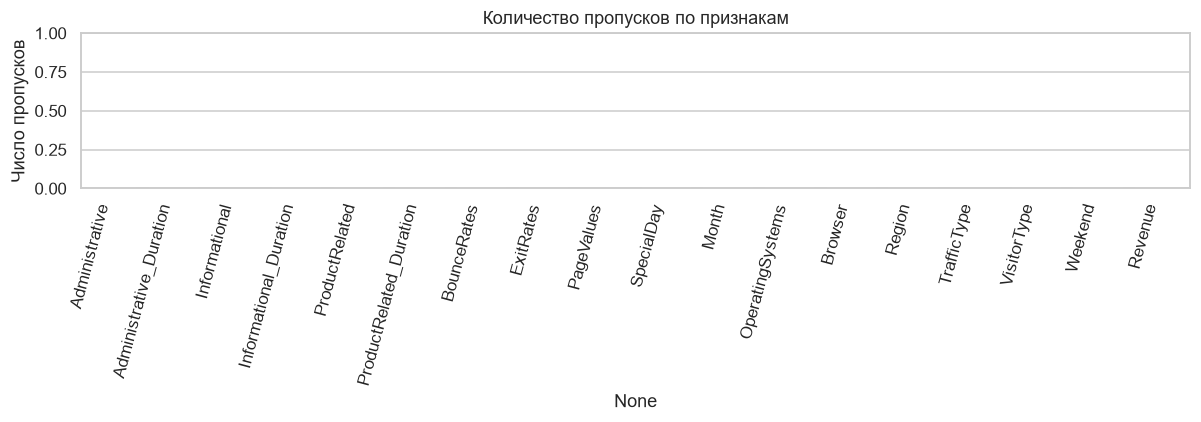

In [6]:
# 5.2 Анализ качества данных
# Количество пропусков по каждому столбцу
missing = df.isna().sum()
print('Всего пропусков в датасете:', int(missing.sum()))

# Количество полностью повторяющихся строк (разные сессии могут совпасть случайно, поэтому их не удаляем)
print('Полных дубликатов строк:', int(df.duplicated().sum()))

# Проверка «скрытых пропусков»: отрицательные значения длительностей невозможны физически
dur_cols = ['Administrative_Duration', 'Informational_Duration', 'ProductRelated_Duration']
neg_counts = (df[dur_cols] < 0).sum()
print('\nОтрицательные значения длительностей:')
print(neg_counts.to_string())

# Визуализация пропусков: столбчатая диаграмма по столбцам
fig, ax = plt.subplots(figsize=(11, 4))
sns.barplot(x=missing.index, y=missing.values, color='steelblue', ax=ax)
ax.set_title('Количество пропусков по признакам')
ax.set_ylabel('Число пропусков')
ax.set_ylim(0, max(1, missing.max()))        # чтобы ось не схлопывалась, когда пропусков нет
plt.xticks(rotation=75, ha='right')
plt.tight_layout()
plt.show()

In [7]:
# 5.3 Обработка пропусков и аномалий
# Отрицательные длительности — технический маркер «нет данных», заменяем нулём
df[dur_cols] = df[dur_cols].clip(lower=0)

# Универсальная защита: если бы пропуски были, числовые заполнили бы медианой, категориальные — модой
for col in df.select_dtypes('number').columns:
    if df[col].isna().any():
        df[col] = df[col].fillna(df[col].median())
for col in df.select_dtypes('object').columns:
    if df[col].isna().any():
        df[col] = df[col].fillna(df[col].mode()[0])

# Контроль: после обработки пропусков и отрицательных длительностей быть не должно
assert df.isna().sum().sum() == 0
assert (df[dur_cols] >= 0).all().all()
print('Данные чистые: пропусков нет, отрицательных длительностей нет.')

Данные чистые: пропусков нет, отрицательных длительностей нет.


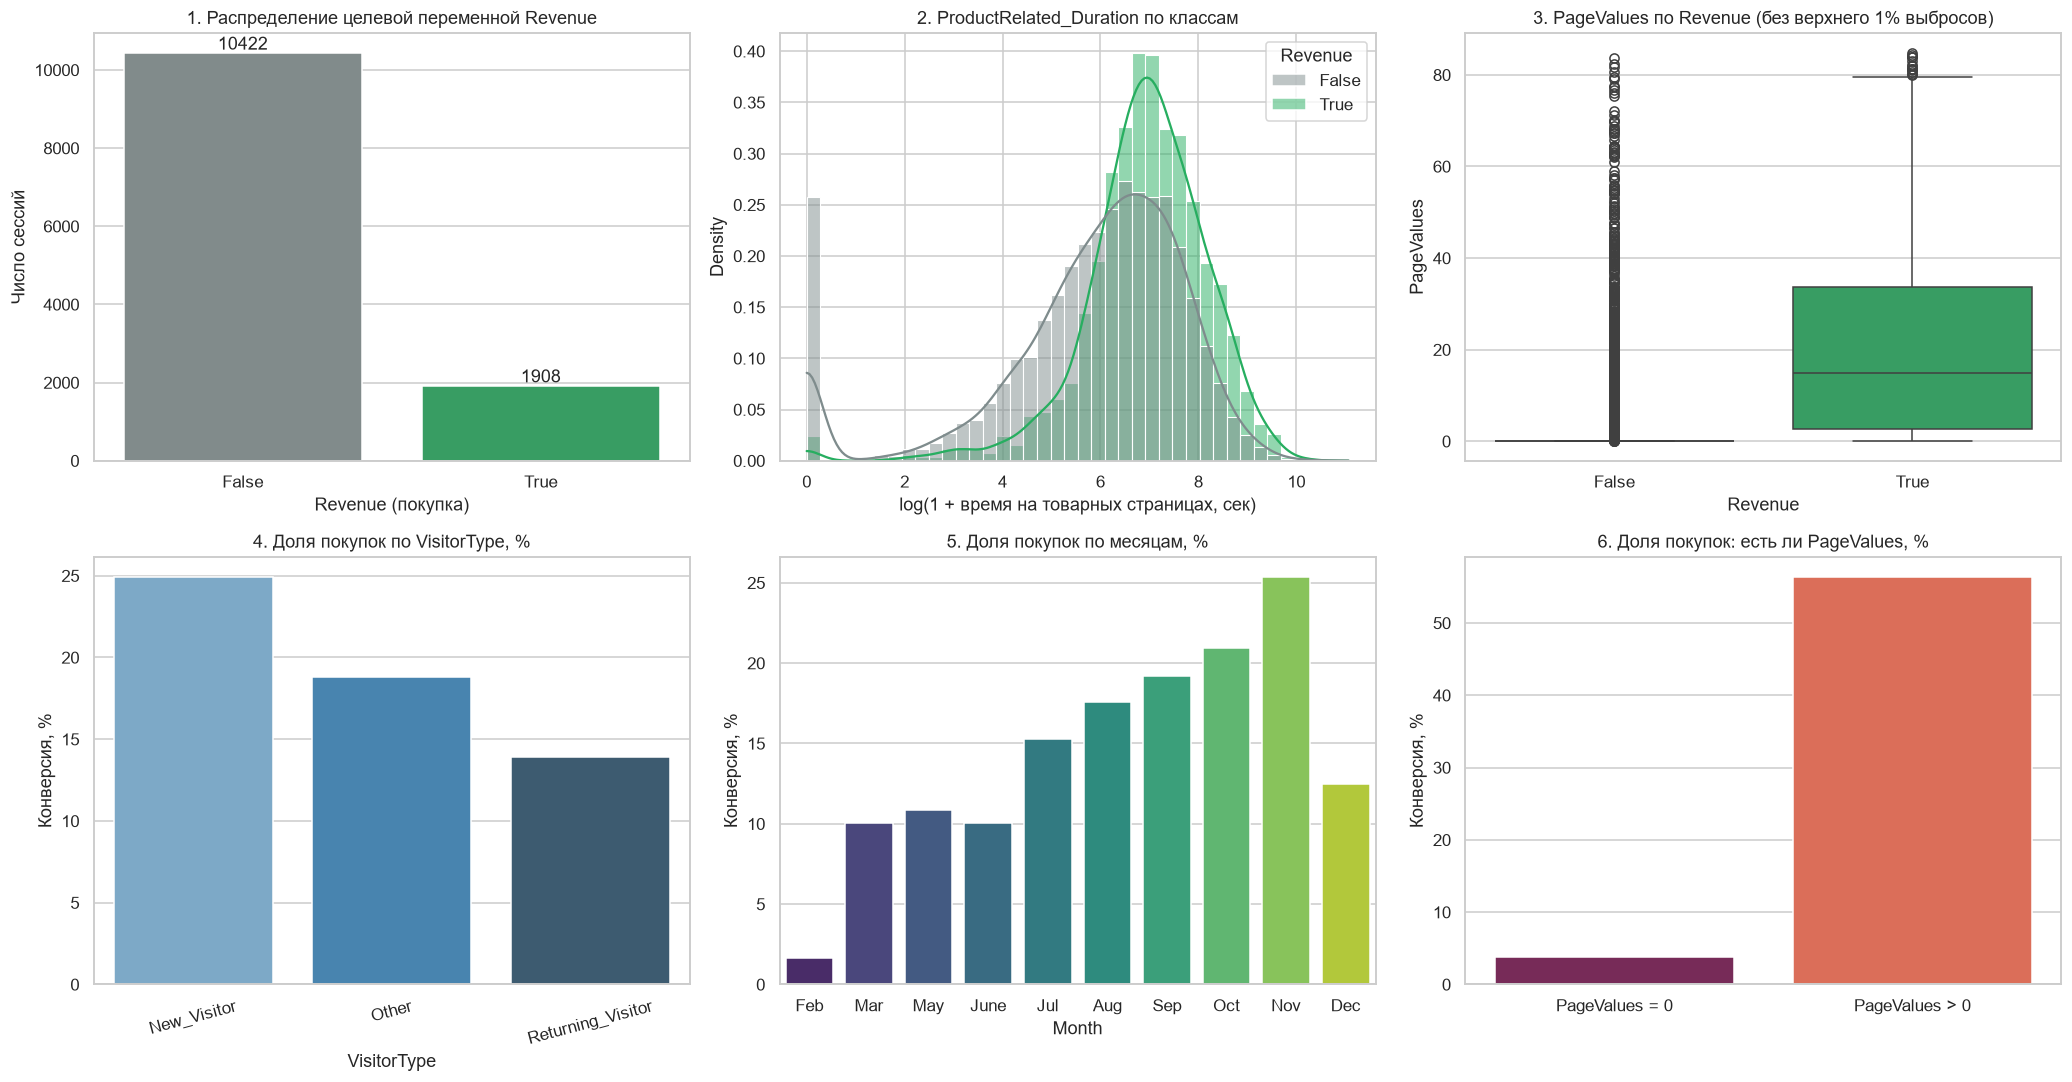

In [8]:
# 5.4 EDA: сетка из 6 графиков (Revenue пока в булевом виде — удобно для hue)
month_order = ['Feb', 'Mar', 'May', 'June', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
month_order = [m for m in month_order if m in df['Month'].unique()]   # оставляем только реально встречающиеся

fig, axes = plt.subplots(2, 3, figsize=(19, 10))

# График 1. Countplot — баланс классов целевой переменной
sns.countplot(data=df, x='Revenue', ax=axes[0, 0], palette=['#7f8c8d', '#27ae60'])
axes[0, 0].set_title('1. Распределение целевой переменной Revenue')
axes[0, 0].set_xlabel('Revenue (покупка)')
axes[0, 0].set_ylabel('Число сессий')
for p in axes[0, 0].patches:                                           # подписываем столбики значениями
    axes[0, 0].annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                        ha='center', va='bottom')

# График 2. Гистограмма времени на товарных страницах (лог-шкала из-за тяжёлого правого хвоста)
sns.histplot(x=np.log1p(df['ProductRelated_Duration']), hue=df['Revenue'], kde=True, stat='density',
             common_norm=False, bins=40, ax=axes[0, 1], palette=['#7f8c8d', '#27ae60'])
axes[0, 1].set_title('2. ProductRelated_Duration по классам')
axes[0, 1].set_xlabel('log(1 + время на товарных страницах, сек)')

# График 3. Boxplot PageValues; обрезаем верхний 1% для читаемости
pv_cap = df['PageValues'].quantile(0.99)
sns.boxplot(data=df[df['PageValues'] <= pv_cap], x='Revenue', y='PageValues', ax=axes[0, 2],
            palette=['#7f8c8d', '#27ae60'])
axes[0, 2].set_title('3. PageValues по Revenue (без верхнего 1% выбросов)')

# График 4. Конверсия по типу посетителя
conv_vis = df.groupby('VisitorType')['Revenue'].mean().mul(100).reset_index()
sns.barplot(data=conv_vis, x='VisitorType', y='Revenue', ax=axes[1, 0], palette='Blues_d')
axes[1, 0].set_title('4. Доля покупок по VisitorType, %')
axes[1, 0].set_ylabel('Конверсия, %')
axes[1, 0].tick_params(axis='x', rotation=15)

# График 5. Конверсия по месяцам (в календарном порядке)
conv_month = df.groupby('Month')['Revenue'].mean().reindex(month_order).mul(100).reset_index()
sns.barplot(data=conv_month, x='Month', y='Revenue', ax=axes[1, 1], palette='viridis')
axes[1, 1].set_title('5. Доля покупок по месяцам, %')
axes[1, 1].set_ylabel('Конверсия, %')

# График 6. Конверсия в зависимости от того, были ли у сессии «ценные» страницы (PageValues > 0)
conv_pv = (df.assign(HasPageValue=np.where(df['PageValues'] > 0, 'PageValues > 0', 'PageValues = 0'))
             .groupby('HasPageValue')['Revenue'].mean().mul(100).reset_index())
sns.barplot(data=conv_pv, x='HasPageValue', y='Revenue', ax=axes[1, 2], palette='rocket')
axes[1, 2].set_title('6. Доля покупок: есть ли PageValues, %')
axes[1, 2].set_xlabel('')
axes[1, 2].set_ylabel('Конверсия, %')

plt.tight_layout()
plt.savefig('examples/eda_plots.png', dpi=150, bbox_inches='tight')   # сохраняем для репозитория
plt.show()

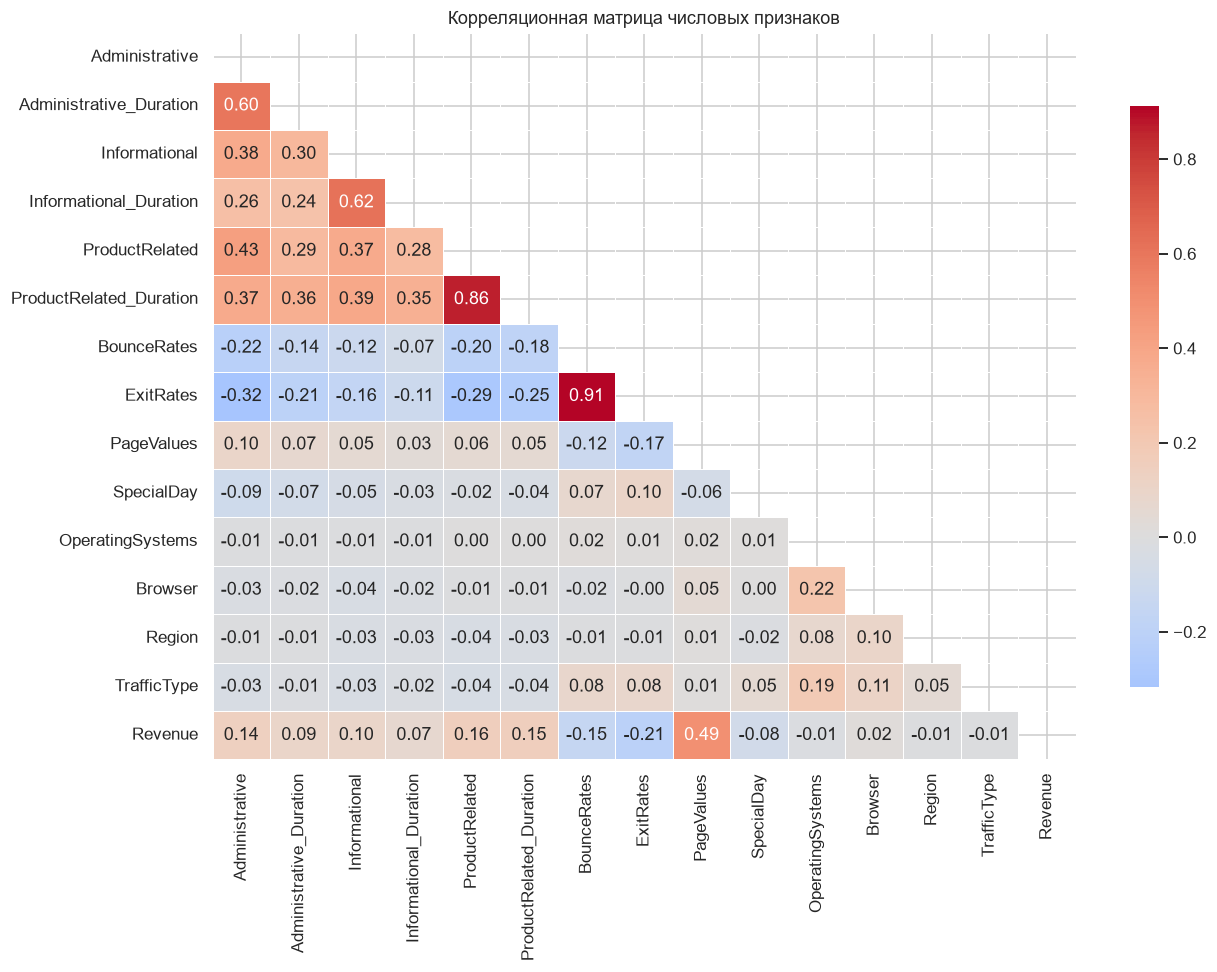

Корреляция с Revenue (по убыванию |r|):
PageValues                 0.493
ExitRates                 -0.207
ProductRelated             0.159
ProductRelated_Duration    0.152
BounceRates               -0.151
Administrative             0.139
Informational              0.095
Administrative_Duration    0.094
SpecialDay                -0.082
Informational_Duration     0.070
Browser                    0.024
OperatingSystems          -0.015
Region                    -0.012
TrafficType               -0.005


In [9]:
# 5.5 Корреляционная матрица числовых признаков (+ целевая в числовом виде)
corr_df = df.select_dtypes('number').copy()
corr_df['Revenue'] = df['Revenue'].astype(int)
corr = corr_df.corr()

# Маска верхнего треугольника, чтобы не дублировать значения
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(12, 9))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            linewidths=0.5, cbar_kws={'shrink': 0.8})
plt.title('Корреляционная матрица числовых признаков')
plt.tight_layout()
plt.savefig('examples/eda_correlation.png', dpi=150, bbox_inches='tight')
plt.show()

# Признаки, сильнее всего связанные с целевой переменной (по модулю корреляции)
print('Корреляция с Revenue (по убыванию |r|):')
print(corr['Revenue'].drop('Revenue').sort_values(key=np.abs, ascending=False).round(3).to_string())

**Выводы по EDA.**  
- Классы несбалансированы (график 1) — покупок существенно меньше, чем сессий без покупки.
- Распределения времени и страниц имеют тяжёлые правые хвосты, поэтому для графиков применён логарифм; для деревьев преобразование не обязательно.
- Самый заметный сигнал даёт `PageValues` (графики 3 и 6): сессии без «ценных» страниц практически не завершаются покупкой.
- Конверсия заметно различается по месяцам и типам посетителей (графики 4–5) — это обоснование для временных и поведенческих признаков.
- В корреляционной матрице сильно коррелируют пары `BounceRates`–`ExitRates` и «число страниц»–«время на них»; это подсказывает, что суммарные признаки (`TotalPages`, `TotalDuration`) будут информативны, а коллинеарность деревьям не мешает.

Подробные цифры — в выводах ячеек выше.

### 5.6. Feature Engineering — какие признаки создаём и зачем

| Признак | Формула | Обоснование |
|---|---|---|
| `TotalPages` | Administrative + Informational + ProductRelated | Общая глубина сессии |
| `TotalDuration` | сумма трёх длительностей | Общее время вовлечения |
| `AvgPageValue` | PageValues / (TotalPages + 1) | Ценность страниц, нормированная на длину сессии |
| `BounceExitRatio` | BounceRates / (ExitRates + 0.001) | Показывает, насколько выходы «жёсткие» (сразу уходят) |
| `AvgTimePerPage` | TotalDuration / (TotalPages + 1) | Быстрый просмотр или вдумчивое чтение |
| `ProductPageShare` | ProductRelated / (TotalPages + 1) | Доля товарных страниц: покупательский интерес |
| `ProductDurationShare` | ProductRelated_Duration / (TotalDuration + 1) | Доля времени на товарах |
| `PageValues_x_Duration` | PageValues · TotalDuration | Взаимодействие: ценность × вовлечённость |
| `IsNewVisitor`, `IsReturningVisitor` | флаги из `VisitorType` | One-Hot для типа посетителя (`Other` — базовая категория) |
| `IsWeekend` | Weekend → 0/1 | Числовая форма булева признака |
| `MonthNum` | Month → 1…12 | Сезонность (порядковая) |
| `MonthSin`, `MonthCos` | sin/cos(2π·MonthNum/12) | Циклическое кодирование: декабрь рядом с январём |
| `IsHighTraffic` | TrafficType > 10 | Группа редких источников трафика |
| `IsSpecialDay` | SpecialDay > 0 | Сессия рядом с особым днём |

Идентификаторы `OperatingSystems`, `Browser`, `Region`, `TrafficType` кодируем One-Hot (номинальные категории без порядка). Целевых данных при построении признаков **не используем** — утечки нет.

In [10]:
# 5.7 Создание новых признаков (работаем с копией, исходный df не трогаем)
fe = df.copy()

# Кодируем целевую переменную: True -> 1, False -> 0
fe['Revenue'] = fe['Revenue'].astype(int)

# --- Агрегаты по сессии ---
fe['TotalPages'] = fe['Administrative'] + fe['Informational'] + fe['ProductRelated']
fe['TotalDuration'] = (fe['Administrative_Duration'] + fe['Informational_Duration']
                       + fe['ProductRelated_Duration'])

# --- Отношения и доли (+1 / +0.001 в знаменателе защищают от деления на ноль) ---
fe['AvgPageValue'] = fe['PageValues'] / (fe['TotalPages'] + 1)
fe['BounceExitRatio'] = fe['BounceRates'] / (fe['ExitRates'] + 0.001)
fe['AvgTimePerPage'] = fe['TotalDuration'] / (fe['TotalPages'] + 1)
fe['ProductPageShare'] = fe['ProductRelated'] / (fe['TotalPages'] + 1)
fe['ProductDurationShare'] = fe['ProductRelated_Duration'] / (fe['TotalDuration'] + 1)

# --- Взаимодействие признаков ---
fe['PageValues_x_Duration'] = fe['PageValues'] * fe['TotalDuration']

# --- Поведенческие флаги ---
fe['IsNewVisitor'] = (fe['VisitorType'] == 'New_Visitor').astype(int)
fe['IsReturningVisitor'] = (fe['VisitorType'] == 'Returning_Visitor').astype(int)
fe['IsWeekend'] = fe['Weekend'].astype(int)
fe['IsHighTraffic'] = (fe['TrafficType'] > 10).astype(int)
fe['IsSpecialDay'] = (fe['SpecialDay'] > 0).astype(int)

# --- Временные признаки: месяц -> число (явный словарь, т.к. 'June' не разбирается форматом %b) ---
month_map = {'Jan': 1, 'Feb': 2, 'Mar': 3, 'Apr': 4, 'May': 5, 'June': 6, 'Jun': 6,
             'Jul': 7, 'Aug': 8, 'Sep': 9, 'Oct': 10, 'Nov': 11, 'Dec': 12}
fe['MonthNum'] = fe['Month'].map(month_map)
assert fe['MonthNum'].notna().all(), 'Есть месяц, которого нет в словаре month_map'

# Циклическое кодирование месяца
fe['MonthSin'] = np.sin(2 * np.pi * fe['MonthNum'] / 12)
fe['MonthCos'] = np.cos(2 * np.pi * fe['MonthNum'] / 12)

# Список созданных признаков (для анализа и отчёта)
new_features = ['TotalPages', 'TotalDuration', 'AvgPageValue', 'BounceExitRatio', 'AvgTimePerPage',
                'ProductPageShare', 'ProductDurationShare', 'PageValues_x_Duration',
                'IsNewVisitor', 'IsReturningVisitor', 'IsWeekend', 'IsHighTraffic', 'IsSpecialDay',
                'MonthNum', 'MonthSin', 'MonthCos']
print(f'Создано новых признаков: {len(new_features)}')

# Быстрая проверка полезности: корреляция новых признаков с целевой
print('\nКорреляция новых признаков с Revenue:')
print(fe[new_features + ['Revenue']].corr()['Revenue'].drop('Revenue')
        .sort_values(key=np.abs, ascending=False).round(3).to_string())

Создано новых признаков: 16

Корреляция новых признаков с Revenue:
AvgPageValue             0.391
PageValues_x_Duration    0.354
TotalPages               0.164
TotalDuration            0.156
MonthSin                -0.143
BounceExitRatio         -0.132
MonthNum                 0.127
IsNewVisitor             0.104
IsReturningVisitor      -0.104
MonthCos                 0.103
ProductPageShare         0.088
IsSpecialDay            -0.087
ProductDurationShare     0.072
AvgTimePerPage           0.067
IsHighTraffic           -0.038
IsWeekend                0.029


In [11]:
# 5.8 Кодирование категориальных признаков
# One-Hot для номинальных идентификаторов (получается набор бинарных столбцов 0/1)
cat_cols = ['OperatingSystems', 'Browser', 'Region', 'TrafficType']
fe = pd.get_dummies(fe, columns=cat_cols, prefix=cat_cols, dtype=int)

# Исходные текстовые/булевы столбцы больше не нужны: их информацию несут созданные признаки
fe = fe.drop(columns=['Month', 'VisitorType', 'Weekend'])

# Итоговый список признаков и матрица X / вектор y
feature_cols = [c for c in fe.columns if c != 'Revenue']
X = fe[feature_cols]
y = fe['Revenue']

# Контроль: все признаки должны быть числовыми
assert all(pd.api.types.is_numeric_dtype(t) for t in X.dtypes), 'В X остались нечисловые столбцы'
print('Итоговое число признаков:', len(feature_cols))
print('Примеры One-Hot столбцов:', [c for c in feature_cols if c.startswith('TrafficType_')][:5])

Итоговое число признаков: 76
Примеры One-Hot столбцов: ['TrafficType_1', 'TrafficType_2', 'TrafficType_3', 'TrafficType_4', 'TrafficType_5']


In [12]:
# 5.9 Разбиение на train/test (80/20) со стратификацией по целевой
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

# Проверяем, что доля покупок одинакова в обеих выборках
print('Train:', X_train.shape, '| доля покупок = {:.3f}'.format(y_train.mean()))
print('Test: ', X_test.shape,  '| доля покупок = {:.3f}'.format(y_test.mean()))

# 5.10 Масштабирование (StandardScaler) непрерывных признаков
# Деревьям оно не нужно, поэтому ансамбли обучаем на исходных значениях (проще интерпретировать SHAP).
# Scaler нужен для линейной baseline-модели и сохраняется как артефакт модуля.
scale_cols = ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration',
              'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues',
              'SpecialDay', 'TotalPages', 'TotalDuration', 'AvgPageValue', 'BounceExitRatio',
              'AvgTimePerPage', 'ProductPageShare', 'ProductDurationShare', 'PageValues_x_Duration',
              'MonthNum']

scaler = StandardScaler()
# fit ТОЛЬКО на обучающей выборке — иначе утечка информации из теста
scaler.fit(X_train[scale_cols])

X_train_sc = X_train.copy()
X_test_sc = X_test.copy()
X_train_sc[scale_cols] = scaler.transform(X_train[scale_cols])
X_test_sc[scale_cols] = scaler.transform(X_test[scale_cols])
print('Scaler обучен на', len(scale_cols), 'признаках.')

Train: (9864, 76) | доля покупок = 0.155
Test:  (2466, 76) | доля покупок = 0.155
Scaler обучен на 19 признаках.


**Выводы по разделу 5.**  
Пропусков в данных нет; обнаруженные технические аномалии (отрицательные длительности, если они есть) исправлены. Создано 16 новых признаков трёх типов — агрегаты (`TotalPages`, `TotalDuration`), отношения/доли (`AvgPageValue`, `AvgTimePerPage`, `ProductPageShare`, …) и временные/поведенческие флаги (`MonthNum`, `MonthSin/Cos`, `IsNewVisitor`, …). Идентификаторы устройств, регионов и источников трафика закодированы One-Hot без навязывания порядка. Разбиение 80/20 выполнено со стратификацией — доля покупок в train и test практически совпадает. `StandardScaler` обучен только на train и сохранён для линейной baseline-модели; ансамбли будут обучаться на исходных значениях, что упростит интерпретацию SHAP.

## 6. Построение и обучение моделей

Обучаем четыре ансамблевые модели с компенсацией дисбаланса классов и фиксируем **время обучения** каждой. Для сравнения также обучим простую логистическую регрессию на масштабированных данных (baseline, в сравнение «лучшей» модели не входит).

| Модель | Тип | Основные параметры | Работа с дисбалансом |
|--------|-----|--------------------|----------------------|
| Random Forest | Bagging | `n_estimators=200`, `max_depth=10` | `class_weight='balanced'` |
| XGBoost | Boosting | `n_estimators=200`, `max_depth=6`, `lr=0.1`, `subsample=0.9`, `colsample_bytree=0.9` | `scale_pos_weight` = N₀/N₁ (≈ 5.4) |
| LightGBM | Boosting | `n_estimators=200`, `num_leaves=31`, `max_depth=7`, `lr=0.05` | `class_weight='balanced'` |
| CatBoost | Boosting | `iterations=200`, `depth=6`, `lr=0.1` | `auto_class_weights='Balanced'` |

**Почему эти модели:** RF устойчив к переобучению и работает «из коробки»; XGBoost — универсальный и точный, с регуляризацией; LightGBM очень быстрый; CatBoost хорошо себя чувствует «из коробки» и аккуратно работает с категориями.

In [13]:
# 6.1 Вес положительного класса для XGBoost: отношение числа «нет покупки» к числу «покупка» в train
n_neg, n_pos = (y_train == 0).sum(), (y_train == 1).sum()
spw = n_neg / n_pos
print(f'scale_pos_weight = {spw:.2f}')

# 6.2 Описание моделей в одном словаре
models = {
    'Random Forest': RandomForestClassifier(
        n_estimators=200, max_depth=10, class_weight='balanced',
        random_state=RANDOM_STATE, n_jobs=-1),
    'XGBoost': XGBClassifier(
        n_estimators=200, max_depth=6, learning_rate=0.1,
        subsample=0.9, colsample_bytree=0.9, scale_pos_weight=spw,
        random_state=RANDOM_STATE, eval_metric='logloss', n_jobs=-1),
    'LightGBM': LGBMClassifier(
        n_estimators=200, num_leaves=31, max_depth=7, learning_rate=0.05,
        class_weight='balanced', random_state=RANDOM_STATE, verbose=-1),
    'CatBoost': CatBoostClassifier(
        iterations=200, depth=6, learning_rate=0.1,
        auto_class_weights='Balanced', random_state=RANDOM_STATE, verbose=0),
}

# 6.3 Обучение с замером времени (perf_counter точнее time.time для коротких интервалов)
train_times = {}
for name, model in models.items():
    start = time.perf_counter()
    model.fit(X_train, y_train)
    train_times[name] = time.perf_counter() - start
    print(f'⏱️ Время обучения {name}: {train_times[name]:.3f} сек')

# Короткие имена для дальнейшего использования
rf_model, xgb_model = models['Random Forest'], models['XGBoost']
lgbm_model, cat_model = models['LightGBM'], models['CatBoost']

scale_pos_weight = 5.46
⏱️ Время обучения Random Forest: 0.801 сек
⏱️ Время обучения XGBoost: 0.594 сек
⏱️ Время обучения LightGBM: 0.228 сек
⏱️ Время обучения CatBoost: 1.306 сек


In [14]:
# 6.4 Baseline: логистическая регрессия на масштабированных данных
start = time.perf_counter()
logreg = LogisticRegression(max_iter=2000, class_weight='balanced', random_state=RANDOM_STATE)
logreg.fit(X_train_sc, y_train)
logreg_time = time.perf_counter() - start
print(f'⏱️ Время обучения Logistic Regression (baseline): {logreg_time:.3f} сек')

# Таблица времени обучения
times_df = (pd.Series(train_times, name='Время обучения, сек').round(3)
              .sort_values().to_frame())
display(times_df)

⏱️ Время обучения Logistic Regression (baseline): 0.268 сек


,"Время обучения, сек"
LightGBM,0.228
XGBoost,0.594
Random Forest,0.801
CatBoost,1.306


**Выводы по разделу 6.**  
Все четыре модели обучены с компенсацией дисбаланса классов. Время обучения зафиксировано в таблице выше: как правило, LightGBM и XGBoost обучаются быстрее Random Forest и CatBoost на одинаковом числе итераций/деревьев, но абсолютные значения зависят от железа, поэтому ориентируйтесь на вывод ячейки. Логистическая регрессия служит нижней опорной точкой: если ансамбли заметно её превосходят, это подтверждает, что нелинейности и взаимодействия признаков действительно важны.

## 7. Оценка качества

Считаем на **тестовой выборке**: Accuracy, Precision, Recall, F1, ROC-AUC (основная метрика) и PR-AUC. Порог классификации — 0.5. Далее строим матрицу ошибок лучшей модели и ROC-кривые всех моделей.

In [15]:
# 7.1 Функция оценки: возвращает все метрики одной строкой словаря
def evaluate_model(model, X_eval, y_eval, name, threshold=0.5):
    proba = model.predict_proba(X_eval)[:, 1]            # вероятность класса «покупка»
    pred = (proba >= threshold).astype(int)              # бинарное предсказание по порогу
    return {
        'Model': name,
        'Accuracy':  accuracy_score(y_eval, pred),
        'Precision': precision_score(y_eval, pred, zero_division=0),
        'Recall':    recall_score(y_eval, pred),
        'F1':        f1_score(y_eval, pred),
        'ROC-AUC':   roc_auc_score(y_eval, proba),
        'PR-AUC':    average_precision_score(y_eval, proba),
    }

# 7.2 Метрики четырёх ансамблей
results = [
    evaluate_model(rf_model,   X_test, y_test, 'Random Forest'),
    evaluate_model(xgb_model,  X_test, y_test, 'XGBoost'),
    evaluate_model(lgbm_model, X_test, y_test, 'LightGBM'),
    evaluate_model(cat_model,  X_test, y_test, 'CatBoost'),
]
results_df = pd.DataFrame(results)
results_df['Train time, s'] = results_df['Model'].map(train_times)

# Baseline считаем отдельно (на масштабированных данных) и не включаем в выбор лучшей модели
baseline_row = evaluate_model(logreg, X_test_sc, y_test, 'Logistic Regression (baseline)')

print('Метрики на тестовой выборке (4 ансамбля):')
display(results_df.round(4))
print('\nBaseline:')
display(pd.DataFrame([baseline_row]).round(4))

# 7.3 Лучшая модель по ROC-AUC
best_name = results_df.sort_values('ROC-AUC').iloc[-1]['Model']
best_ensemble = models[best_name]
print(f'\n🏆 Лучшая модель по ROC-AUC: {best_name}')

Метрики на тестовой выборке (4 ансамбля):


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,"Train time, s"
0,Random Forest,0.8674,0.5494,0.8010,0.6518,0.9274,0.7286,0.8006
1,XGBoost,0.8812,0.5969,0.7173,0.6516,0.9217,0.7134,0.5940
2,LightGBM,0.8747,0.5703,0.7749,0.6570,0.9283,0.7292,0.2278
3,CatBoost,0.8698,0.5560,0.7932,0.6537,0.9282,0.7371,1.3058



Baseline:


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Logistic Regression (baseline),0.8427,0.4947,0.7356,0.5916,0.8844,0.6272



🏆 Лучшая модель по ROC-AUC: LightGBM


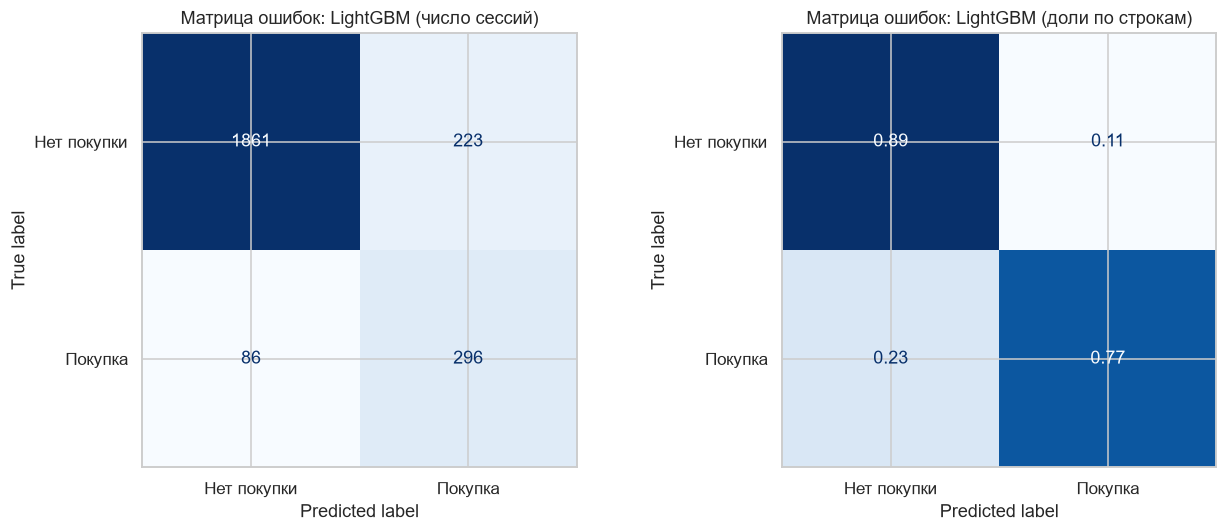

              precision    recall  f1-score   support

 Нет покупки      0.956     0.893     0.923      2084
     Покупка      0.570     0.775     0.657       382

    accuracy                          0.875      2466
   macro avg      0.763     0.834     0.790      2466
weighted avg      0.896     0.875     0.882      2466



In [16]:
# 7.4 Матрица ошибок лучшей модели: абсолютная и нормированная по строкам (по истинным классам)
proba_best = best_ensemble.predict_proba(X_test)[:, 1]
pred_best = (proba_best >= 0.5).astype(int)
labels = ['Нет покупки', 'Покупка']

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(y_test, pred_best, display_labels=labels,
                                        cmap='Blues', ax=axes[0], colorbar=False)
axes[0].set_title(f'Матрица ошибок: {best_name} (число сессий)')
ConfusionMatrixDisplay.from_predictions(y_test, pred_best, display_labels=labels,
                                        cmap='Blues', normalize='true', values_format='.2f',
                                        ax=axes[1], colorbar=False)
axes[1].set_title(f'Матрица ошибок: {best_name} (доли по строкам)')
plt.tight_layout()
plt.show()

# Подробный отчёт по классам
print(classification_report(y_test, pred_best, target_names=labels, digits=3))

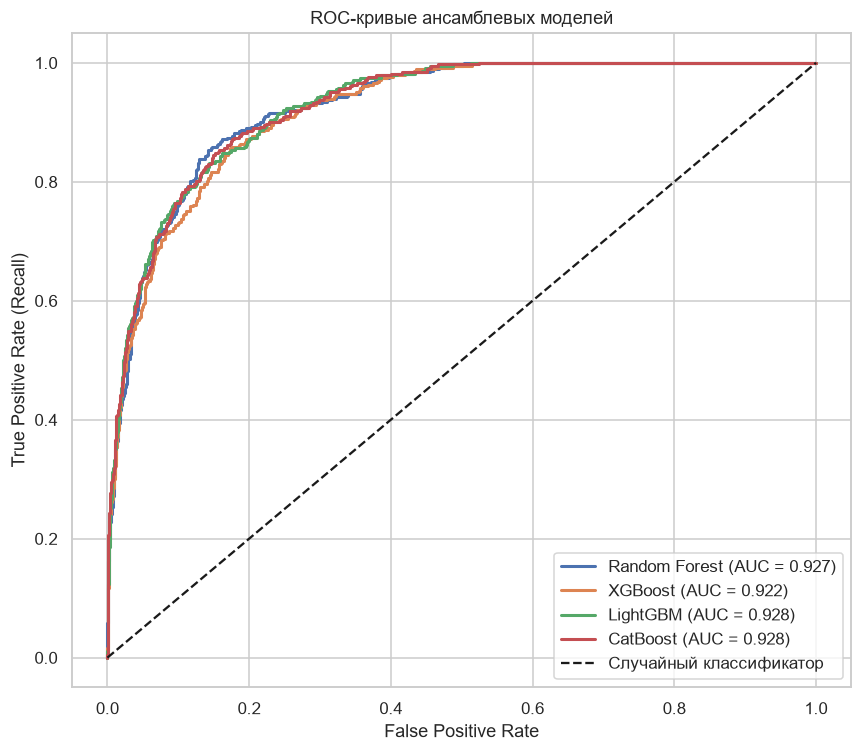

In [17]:
# 7.5 ROC-кривые всех четырёх моделей на одном графике
plt.figure(figsize=(8, 7))
for name, model in models.items():
    proba = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    plt.plot(fpr, tpr, linewidth=2, label=f'{name} (AUC = {auc:.3f})')

# Диагональ — случайный классификатор
plt.plot([0, 1], [0, 1], 'k--', label='Случайный классификатор')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.title('ROC-кривые ансамблевых моделей')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig('examples/roc_curves.png', dpi=150, bbox_inches='tight')
plt.show()

In [18]:
# 7.6 Автоматическая сводка по результатам (текст формируется из реальных метрик)
top = results_df.sort_values('ROC-AUC', ascending=False).reset_index(drop=True)
fastest = results_df.sort_values('Train time, s').iloc[0]
best_recall = results_df.sort_values('Recall', ascending=False).iloc[0]
tn, fp, fn, tp = confusion_matrix(y_test, pred_best).ravel()

display(Markdown(f"""
**Автоматическая сводка:**
- Лучшая модель по ROC-AUC: **{top.loc[0, 'Model']}** ({top.loc[0, 'ROC-AUC']:.4f}); второй — {top.loc[1, 'Model']} ({top.loc[1, 'ROC-AUC']:.4f}).
- Самая быстрая в обучении: **{fastest['Model']}** ({fastest['Train time, s']:.2f} с).
- Наибольший Recall: **{best_recall['Model']}** ({best_recall['Recall']:.3f}).
- Baseline (логрегрессия): ROC-AUC = {baseline_row['ROC-AUC']:.4f} — ансамбли лучше baseline на {top.loc[0, 'ROC-AUC'] - baseline_row['ROC-AUC']:+.4f}.
- Матрица ошибок лучшей модели: найдено покупателей — {tp}, пропущено — {fn}, ложных тревог — {fp}, верных «нет покупки» — {tn}.
"""))


**Автоматическая сводка:**
- Лучшая модель по ROC-AUC: **LightGBM** (0.9283); второй — CatBoost (0.9282).
- Самая быстрая в обучении: **LightGBM** (0.23 с).
- Наибольший Recall: **Random Forest** (0.801).
- Baseline (логрегрессия): ROC-AUC = 0.8844 — ансамбли лучше baseline на +0.0438.
- Матрица ошибок лучшей модели: найдено покупателей — 296, пропущено — 86, ложных тревог — 223, верных «нет покупки» — 1861.


**Выводы по разделу 7.**  
- Из-за дисбаланса Accuracy у всех моделей выглядит высокой и малоинформативна; смотрим на ROC-AUC, F1 и PR-AUC.
- При взвешивании классов модель, как правило, **повышает Recall за счёт Precision**: она чаще «угадывает» покупку, но чаще и ошибается в ложную сторону. Для бизнеса это приемлемо, если стоимость показа скидки ниже упущенной покупки; иначе порог нужно повышать.
- Различия между бустингами обычно невелики (сотые доли ROC-AUC), поэтому выбор модели стоит делать также по скорости и простоте поддержки.
- Конкретные значения и победитель определены в автоматической сводке выше. Для тюнинга по заданию используем LightGBM.

## 8. Интерпретация и бизнес-инсайты

Смотрим, какие признаки важнее всего для Random Forest (средний вклад в снижение неопределённости) и LightGBM (суммарный **gain** по разбиениям), а затем переводим результаты на язык бизнеса.

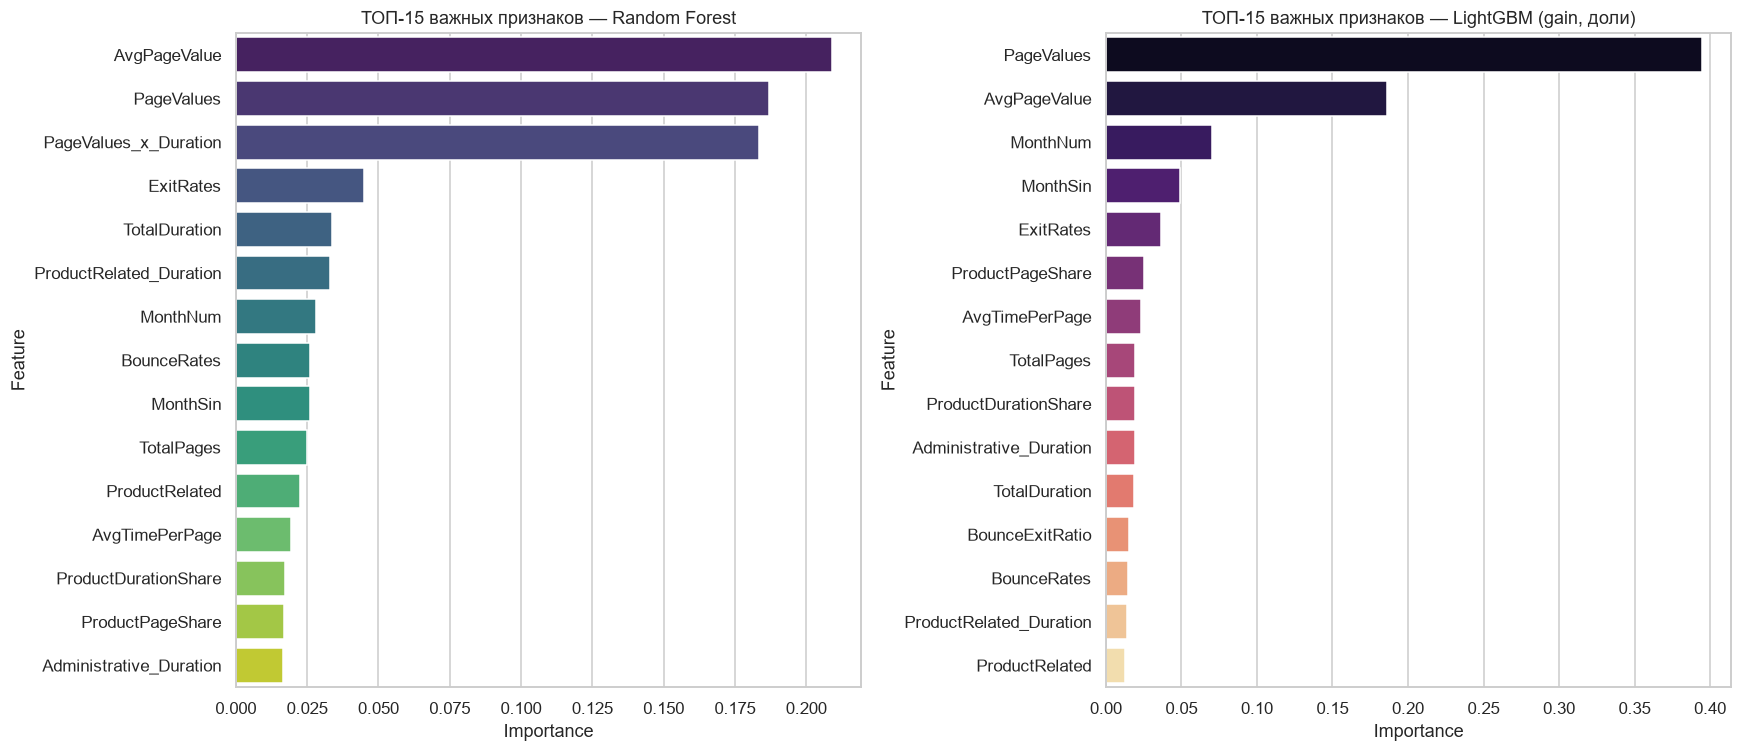

Признаки в ТОП-15 обеих моделей: ['Administrative_Duration', 'AvgPageValue', 'AvgTimePerPage', 'BounceRates', 'ExitRates', 'MonthNum', 'MonthSin', 'PageValues', 'ProductDurationShare', 'ProductPageShare', 'ProductRelated', 'ProductRelated_Duration', 'TotalDuration', 'TotalPages']
Созданные признаки в ТОП-15: ['AvgPageValue', 'AvgTimePerPage', 'BounceExitRatio', 'MonthNum', 'MonthSin', 'PageValues_x_Duration', 'ProductDurationShare', 'ProductPageShare', 'TotalDuration', 'TotalPages']


In [20]:
# 8.1 Важность признаков: RF (impurity) и LightGBM (gain, нормируем в доли для сопоставимости)
rf_imp = pd.Series(rf_model.feature_importances_, index=feature_cols)
lgb_gain = pd.Series(lgbm_model.booster_.feature_importance(importance_type='gain'),
                     index=lgbm_model.booster_.feature_name())
lgb_imp = lgb_gain / lgb_gain.sum()

imp_rf = rf_imp.sort_values(ascending=False).head(15).reset_index()
imp_rf.columns = ['Feature', 'Importance']
imp_lgb = lgb_imp.sort_values(ascending=False).head(15).reset_index()
imp_lgb.columns = ['Feature', 'Importance']

# Два графика рядом: ТОП-15 для каждой модели
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
sns.barplot(data=imp_rf, x='Importance', y='Feature', hue='Feature', palette='viridis',
            legend=False, ax=axes[0])
axes[0].set_title('ТОП-15 важных признаков — Random Forest')
sns.barplot(data=imp_lgb, x='Importance', y='Feature', hue='Feature', palette='magma',
            legend=False, ax=axes[1])
axes[1].set_title('ТОП-15 важных признаков — LightGBM (gain, доли)')
plt.tight_layout()
plt.savefig('examples/feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

# Признаки, попавшие в топ-15 обеих моделей — наиболее надёжные драйверы
common = sorted(set(imp_rf['Feature']) & set(imp_lgb['Feature']))
print('Признаки в ТОП-15 обеих моделей:', common)

# Какие из СОЗДАННЫХ нами признаков попали в топ-15 хотя бы одной модели
engineered_in_top = sorted((set(imp_rf['Feature']) | set(imp_lgb['Feature'])) & set(new_features))
print('Созданные признаки в ТОП-15:', engineered_in_top)

In [22]:
# 8.2 Бизнес-таблицы: конверсия по сегментам (на всей выборке, по исходному df)
def conv_table(series, name):
    # доля покупок и размер сегмента
    t = df.groupby(series)['Revenue'].agg(['mean', 'size'])
    t.columns = ['Конверсия', 'Сессий']
    t['Конверсия'] = (t['Конверсия'] * 100).round(2)
    t.index.name = name
    return t

display(Markdown('**Конверсия по типу посетителя, %**'))
conv_visitor = conv_table(df['VisitorType'], 'VisitorType'); display(conv_visitor)

display(Markdown('**Конверсия по месяцам, %**'))
display(conv_table(df['Month'], 'Month').reindex(month_order))

display(Markdown('**Конверсия: выходной / будний день, %**'))
display(conv_table(df['Weekend'], 'Weekend'))

display(Markdown('**Конверсия: близость к особому дню (SpecialDay), %**'))
display(conv_table(df['SpecialDay'], 'SpecialDay'))

display(Markdown('**Конверсия: есть ли PageValues > 0, %**'))
display(conv_table(np.where(df['PageValues'] > 0, 'PageValues > 0', 'PageValues = 0'), 'Группа'))

# Автоматический вывод по новым и вернувшимся посетителям
new_c, ret_c = conv_visitor.loc['New_Visitor', 'Конверсия'], conv_visitor.loc['Returning_Visitor', 'Конверсия']
word = 'выше' if new_c > ret_c else 'ниже'
display(Markdown(f'**Вывод:** конверсия новых посетителей ({new_c:.1f}%) {word}, чем возвращающихся ({ret_c:.1f}%).'))

**Конверсия по типу посетителя, %**

,Конверсия,Сессий
VisitorType,,
New_Visitor,24.91,1694
Other,18.82,85
Returning_Visitor,13.93,10551


**Конверсия по месяцам, %**

,Конверсия,Сессий
Month,,
Feb,1.63,184
Mar,10.07,1907
May,10.85,3364
June,10.07,288
Jul,15.28,432
Aug,17.55,433
Sep,19.20,448
Oct,20.95,549
Nov,25.35,2998


**Конверсия: выходной / будний день, %**

...

**Конверсия: близость к особому дню (SpecialDay), %**

,Конверсия,Сессий
SpecialDay,,
0.0,16.53,11079
0.2,7.87,178
0.4,5.35,243
0.6,8.26,351
0.8,3.38,325
1.0,6.49,154


**Конверсия: есть ли PageValues > 0, %**

,Конверсия,Сессий
Группа,,
PageValues = 0,3.85,9600
PageValues > 0,56.34,2730


**Вывод:** конверсия новых посетителей (24.9%) выше, чем возвращающихся (13.9%).

**Выводы по разделу 8 и бизнес-инсайты.**

Конкретный рейтинг признаков смотрите на графиках выше.

1. **`PageValues`** (и производные `AvgPageValue`, `PageValues_x_Duration`) — главный предиктор: сессии, в которых пользователь видел страницы, исторически ведущие к транзакции, конвертируются многократно чаще. *Что делать:* выводить такие страницы раньше в пользовательском пути, усиливать на них призывы к действию.
2. **`ExitRates` / `BounceRates` и `BounceExitRatio`** — высокие значения сигнализируют о «слабых» страницах. *Что делать:* A/B-тесты посадочных страниц, ускорение загрузки, ревизия контента на страницах с наибольшими выходами.
3. **Вовлечённость на товарных страницах** (`ProductRelated`, `ProductRelated_Duration`, `TotalDuration`, доли) — интерес к каталогу повышает шанс покупки. *Что делать:* рекомендательные блоки «похожие товары», сравнение товаров, быстрые фильтры.
4. **Сезонность** (`MonthNum`, `MonthSin/Cos`) — конверсия заметно меняется по месяцам (см. таблицу). *Что делать:* планировать бюджеты и акции под сильные месяцы, готовить сайт к пикам нагрузки.
5. **Тип посетителя** — сравните конверсию новых и вернувшихся по таблице: направление эффекта определяется данными, а не ожиданиями. *Что делать:* для сегмента с низкой конверсией — онбординг, приветственные скидки или программа лояльности.

Практический сценарий использования модели: в реальном времени оценивать вероятность покупки в ходе сессии и запускать триггеры (чат с консультантом, промокод, напоминание) только для сессий в «средней зоне» вероятности, где вмешательство даёт наибольший эффект. Полезно сверить важность признаков с SHAP (раздел 10): встроенная важность не показывает направление влияния.

## 9. Тюнинг гиперпараметров (Optuna)

По условию задания тюним **LightGBM**. Используем байесовскую оптимизацию Optuna (сэмплер TPE) и целевую функцию — средний ROC-AUC по 5-кратной стратифицированной кросс-валидации **на обучающей выборке**. Тестовая выборка в подборе не участвует, поэтому итоговое сравнение честное.

Замечание по параметрам: в LightGBM `subsample` действует только при `subsample_freq > 0`, поэтому задаём `subsample_freq=1`.

In [23]:
import optuna
from optuna.importance import get_param_importances
optuna.logging.set_verbosity(optuna.logging.WARNING)      # меньше шума в выводе

# Единые фолды для всех сравнений (чтобы baseline и Optuna сравнивались на одинаковом разбиении)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def objective(trial):
    # Пространство поиска гиперпараметров
    params = {
        'n_estimators':      trial.suggest_int('n_estimators', 100, 500, step=50),
        'num_leaves':        trial.suggest_int('num_leaves', 10, 100, step=5),
        'max_depth':         trial.suggest_int('max_depth', 3, 12),
        'learning_rate':     trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'subsample':         trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree':  trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'min_child_samples': trial.suggest_int('min_child_samples', 5, 50),
        'reg_alpha':         trial.suggest_float('reg_alpha', 1e-3, 10, log=True),
        'reg_lambda':        trial.suggest_float('reg_lambda', 1e-3, 10, log=True),
    }
    model = LGBMClassifier(**params, subsample_freq=1, class_weight='balanced',
                           random_state=RANDOM_STATE, verbose=-1)
    # Средний ROC-AUC по 5 фолдам на TRAIN — то, что максимизируем
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='roc_auc')
    return scores.mean()

# CV-качество baseline-LightGBM на тех же фолдах — точка отсчёта для Optuna
baseline_cv = cross_val_score(
    LGBMClassifier(n_estimators=200, num_leaves=31, max_depth=7, learning_rate=0.05,
                   class_weight='balanced', random_state=RANDOM_STATE, verbose=-1),
    X_train, y_train, cv=cv, scoring='roc_auc').mean()
print(f'Baseline LightGBM, CV ROC-AUC (train): {baseline_cv:.4f}')

# Запуск оптимизации: 30 испытаний (по заданию минимум 20)
study = optuna.create_study(direction='maximize',
                            sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study.optimize(objective, n_trials=30, show_progress_bar=True)

print(f'\nЛучший CV ROC-AUC (Optuna): {study.best_value:.4f}')
print('Лучшие параметры:')
for key, value in study.best_params.items():
    print(f'  {key}: {value}')

Baseline LightGBM, CV ROC-AUC (train): 0.9305


  0%|          | 0/30 [00:00<?, ?it/s]


Лучший CV ROC-AUC (Optuna): 0.9358
Лучшие параметры:
  n_estimators: 300
  num_leaves: 45
  max_depth: 7
  learning_rate: 0.011575543666882692
  subsample: 0.8279993205960767
  colsample_bytree: 0.5311540154297647
  min_child_samples: 48
  reg_alpha: 0.6404825703012398
  reg_lambda: 0.06115185079793613


In [24]:
# 9.2 Финальная модель с лучшими параметрами; обучаем на всём train, оцениваем на test
best_params_full = {**study.best_params, 'subsample_freq': 1}
best_lgbm = LGBMClassifier(**best_params_full, class_weight='balanced',
                           random_state=RANDOM_STATE, verbose=-1)
best_lgbm.fit(X_train, y_train)

# Метрики до и после тюнинга на тестовой выборке
base_metrics = evaluate_model(lgbm_model, X_test, y_test, 'LightGBM (baseline)')
tuned_metrics = evaluate_model(best_lgbm, X_test, y_test, 'LightGBM (Optuna)')
compare_df = pd.DataFrame([base_metrics, tuned_metrics])
display(compare_df.round(4))

# Вероятности настроенной модели нужны для SHAP и последующих разделов
y_proba_best = best_lgbm.predict_proba(X_test)[:, 1]
y_pred_best = (y_proba_best >= 0.5).astype(int)

delta_auc = tuned_metrics['ROC-AUC'] - base_metrics['ROC-AUC']
print(f"ROC-AUC baseline: {base_metrics['ROC-AUC']:.4f}")
print(f"ROC-AUC Optuna:   {tuned_metrics['ROC-AUC']:.4f}  (изменение {delta_auc:+.4f})")
print(f'CV ROC-AUC: {baseline_cv:.4f} -> {study.best_value:.4f}  (изменение {study.best_value - baseline_cv:+.4f})')

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,LightGBM (baseline),0.8747,0.5703,0.7749,0.6570,0.9283,0.7292
1,LightGBM (Optuna),0.8678,0.5484,0.8298,0.6604,0.9330,0.7524


ROC-AUC baseline: 0.9283
ROC-AUC Optuna:   0.9330  (изменение +0.0048)
CV ROC-AUC: 0.9305 -> 0.9358  (изменение +0.0053)


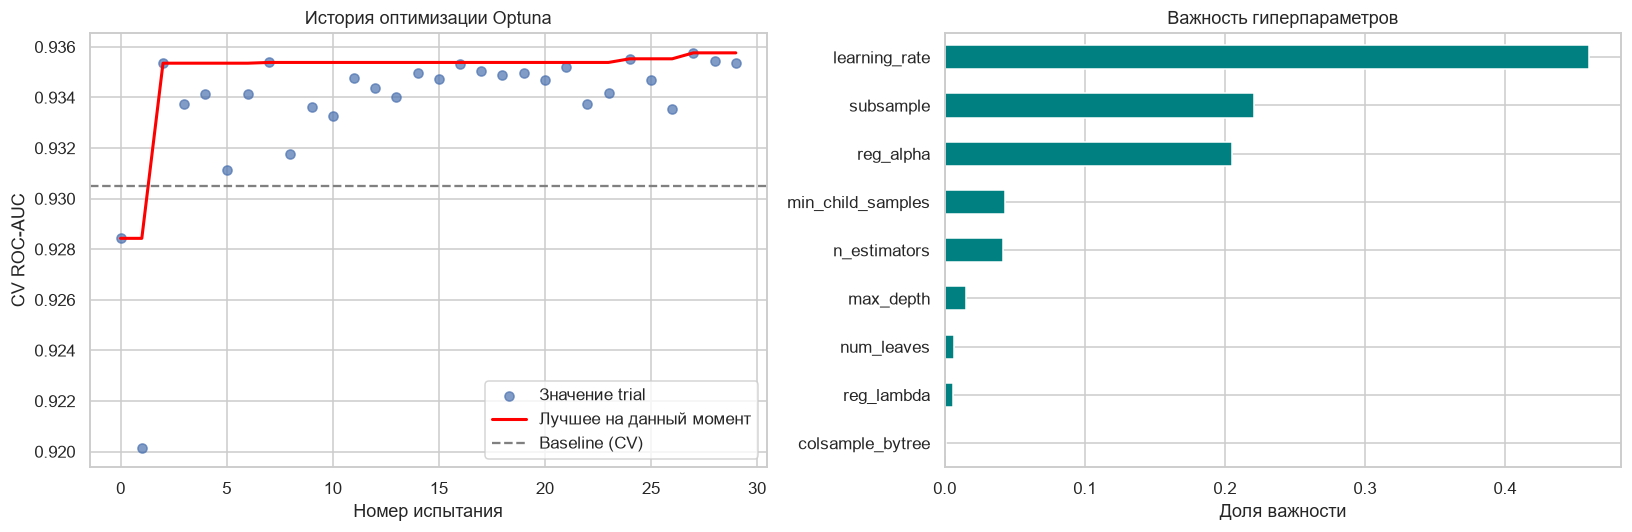

In [25]:
# 9.3 Визуализация процесса оптимизации и важности гиперпараметров
trials_df = study.trials_dataframe()
best_so_far = trials_df['value'].cummax()                 # лучшее значение на каждом шаге

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# История оптимизации
axes[0].scatter(trials_df['number'], trials_df['value'], label='Значение trial', alpha=0.7)
axes[0].plot(trials_df['number'], best_so_far, color='red', linewidth=2, label='Лучшее на данный момент')
axes[0].axhline(baseline_cv, color='gray', linestyle='--', label='Baseline (CV)')
axes[0].set_xlabel('Номер испытания'); axes[0].set_ylabel('CV ROC-AUC')
axes[0].set_title('История оптимизации Optuna'); axes[0].legend()

# Важность гиперпараметров (по оценке Optuna)
param_imp = pd.Series(get_param_importances(study)).sort_values()
param_imp.plot(kind='barh', ax=axes[1], color='teal')
axes[1].set_title('Важность гиперпараметров'); axes[1].set_xlabel('Доля важности')

plt.tight_layout()
plt.show()

### 9.4. Бонус: калибровка вероятностей

Из-за `class_weight='balanced'` модель систематически **завышает** вероятность покупки: её выходы удобны для ранжирования, но не равны реальным частотам. Если вероятности используются в бизнес-расчётах (ожидаемая выручка, стоимость скидки), их нужно калибровать. Применим изотоническую регрессию через `CalibratedClassifierCV` (внутри — 5-кратная кросс-валидация на train) и сравним **Brier score** (чем меньше, тем лучше) и калибровочные кривые.

Brier score до калибровки:    0.0981
Brier score после калибровки: 0.0692
ROC-AUC до/после: 0.9330 / 0.9333


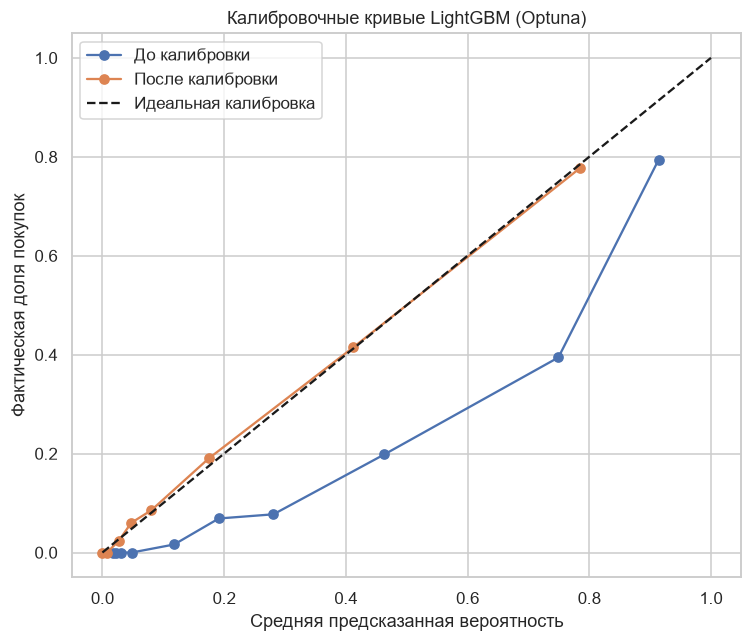

In [26]:
from sklearn.calibration import CalibratedClassifierCV, calibration_curve

# Калибруем копию настроенной модели (изотоническая регрессия, 5 фолдов на train)
cal_model = CalibratedClassifierCV(
    LGBMClassifier(**best_params_full, class_weight='balanced',
                   random_state=RANDOM_STATE, verbose=-1),
    method='isotonic', cv=5)
cal_model.fit(X_train, y_train)
proba_cal = cal_model.predict_proba(X_test)[:, 1]

# Brier score: средний квадрат ошибки вероятности
brier_raw = brier_score_loss(y_test, y_proba_best)
brier_cal = brier_score_loss(y_test, proba_cal)
print(f'Brier score до калибровки:    {brier_raw:.4f}')
print(f'Brier score после калибровки: {brier_cal:.4f}')
print(f"ROC-AUC до/после: {roc_auc_score(y_test, y_proba_best):.4f} / {roc_auc_score(y_test, proba_cal):.4f}")

# Калибровочные кривые: идеальная модель лежит на диагонали
plt.figure(figsize=(7, 6))
for proba, label in [(y_proba_best, 'До калибровки'), (proba_cal, 'После калибровки')]:
    frac_pos, mean_pred = calibration_curve(y_test, proba, n_bins=10, strategy='quantile')
    plt.plot(mean_pred, frac_pos, marker='o', label=label)
plt.plot([0, 1], [0, 1], 'k--', label='Идеальная калибровка')
plt.xlabel('Средняя предсказанная вероятность'); plt.ylabel('Фактическая доля покупок')
plt.title('Калибровочные кривые LightGBM (Optuna)'); plt.legend()
plt.tight_layout(); plt.show()

calibration_info = {'brier_raw': float(brier_raw), 'brier_calibrated': float(brier_cal)}

**Выводы по разделу 9.**  
Optuna провела 30 испытаний с кросс-валидацией на обучающей выборке; результаты (лучшие параметры, прирост CV- и тестового ROC-AUC) выведены выше. Важно помнить: при уже сильных дефолтных параметрах выигрыш от тюнинга обычно небольшой (порядка сотых–тысячных долей ROC-AUC), а на тесте он может быть даже чуть отрицательным из-за случайных колебаний — это нормальный и честный результат, поскольку тест в подборе не участвовал. Бонусная калибровка показывает, что вероятности «сырой» взвешенной модели смещены; изотоническая калибровка снижает Brier score, почти не меняя ROC-AUC (ранжирование сохраняется).

## 10. Интерпретация через SHAP

Объясняем настроенную модель `best_lgbm`. Строим summary-график (направление и сила влияния), bar-график (средний |SHAP|), waterfall-график для отдельных сессий и dependence-графики для главных признаков. Значения SHAP для LightGBM измеряются в логарифмических шансах (log-odds).

In [27]:
import shap

# 10.1 Объяснитель для древовидной модели и SHAP-значения на тестовой выборке
explainer = shap.TreeExplainer(best_lgbm)
shap_raw = explainer.shap_values(X_test)

# Разные версии shap возвращают разные форматы: список по классам, 3D-массив или 2D-массив
if isinstance(shap_raw, list):
    shap_values_class1 = shap_raw[1]                 # старый формат: [класс 0, класс 1]
elif getattr(shap_raw, 'ndim', 2) == 3:
    shap_values_class1 = shap_raw[:, :, 1]           # (объекты, признаки, классы)
else:
    shap_values_class1 = shap_raw                    # уже вклад в класс «покупка»

# Базовое значение (среднее предсказание по данным) для класса «покупка»
base_value = float(np.ravel(explainer.expected_value)[-1])

# Глобальная важность: средний модуль SHAP по каждому признаку
shap_importance = (pd.Series(np.abs(shap_values_class1).mean(axis=0), index=X_test.columns)
                     .sort_values(ascending=False))
print('ТОП-10 признаков по среднему |SHAP|:')
print(shap_importance.head(10).round(4).to_string())

ТОП-10 признаков по среднему |SHAP|:
AvgPageValue               0.5565
PageValues                 0.5094
MonthNum                   0.4657
MonthSin                   0.3178
PageValues_x_Duration      0.2241
ExitRates                  0.1177
MonthCos                   0.1174
BounceRates                0.0703
Administrative_Duration    0.0578
TotalDuration              0.0489


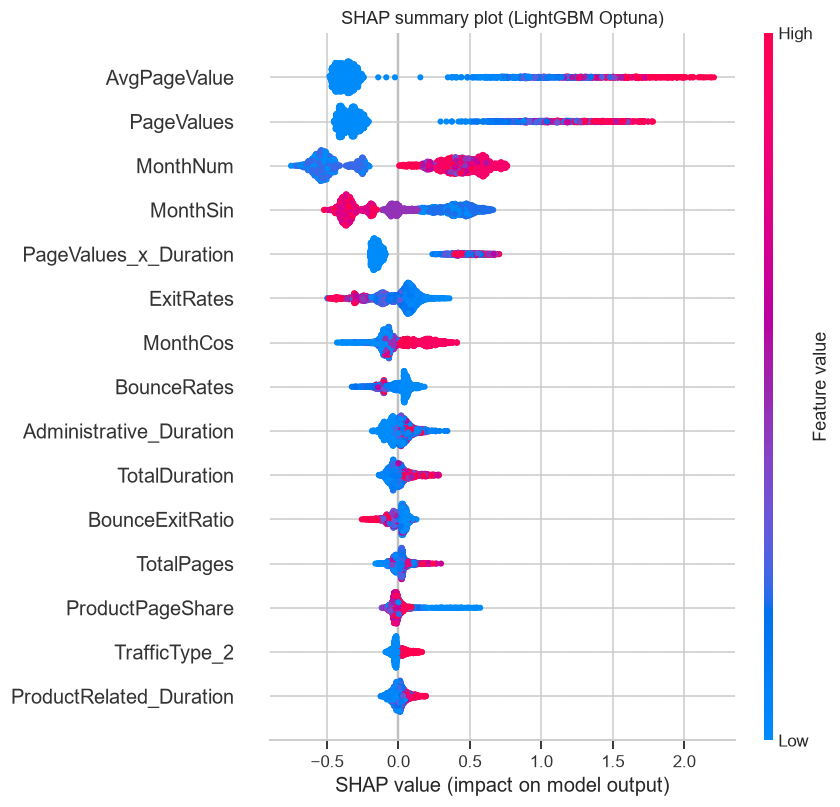

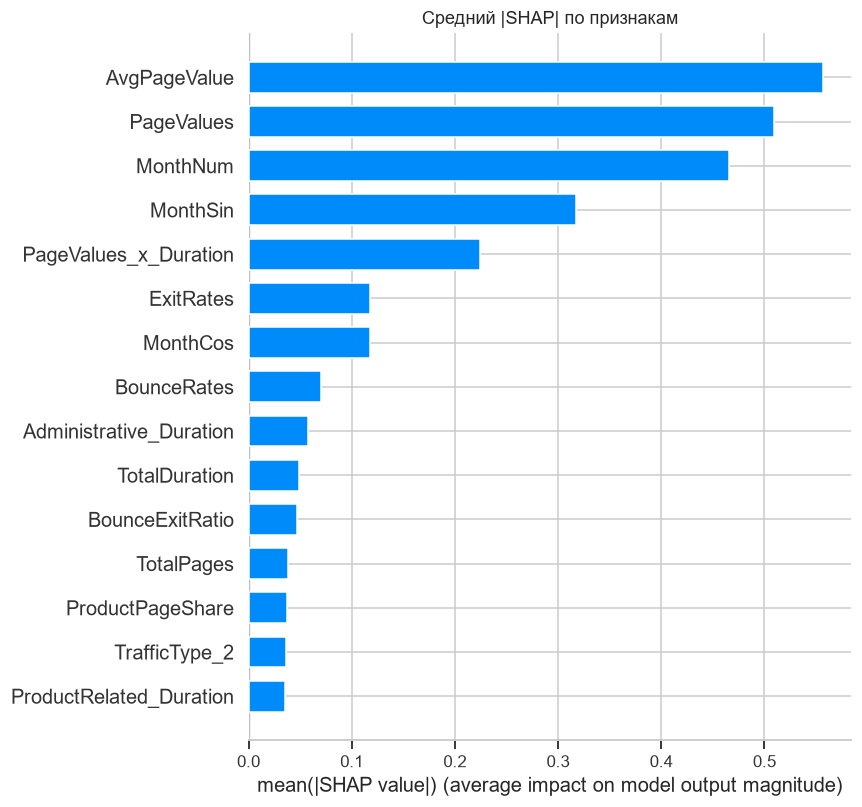

In [28]:
# 10.2 Summary plot (beeswarm): каждая точка — одна сессия; цвет — значение признака
plt.figure()
shap.summary_plot(shap_values_class1, X_test, plot_type='dot', max_display=15, show=False)
plt.title('SHAP summary plot (LightGBM Optuna)')
plt.tight_layout()
plt.savefig('examples/shap_summary.png', dpi=150, bbox_inches='tight')
plt.show()

# 10.3 Bar plot: средний вклад признаков по модулю
plt.figure()
shap.summary_plot(shap_values_class1, X_test, plot_type='bar', max_display=15, show=False)
plt.title('Средний |SHAP| по признакам')
plt.tight_layout()
plt.show()

Сессия (позиция в тесте) #119: вероятность покупки = 0.9696, факт: 1


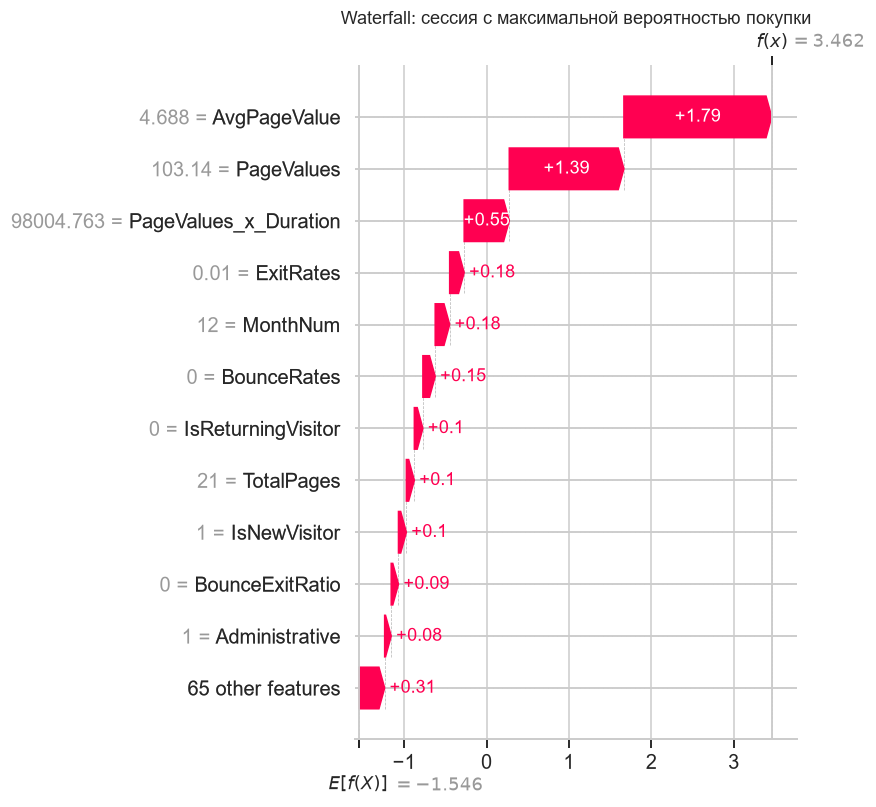


Пропущенный покупатель: позиция #2200, вероятность = 0.1044


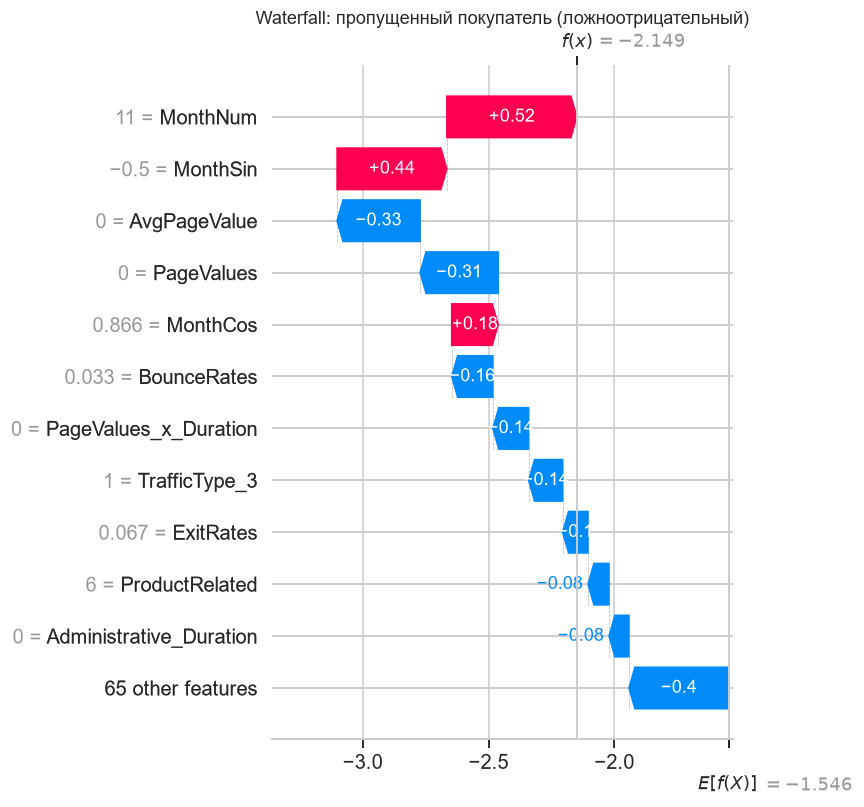

In [29]:
# 10.4 Waterfall plot для двух сессий:
#  (а) сессия с максимальной предсказанной вероятностью покупки;
#  (б) реальный покупатель, которого модель пропустила (если такие есть) — полезно для разбора ошибок
def explain_one(idx_pos, title):
    # idx_pos — позиция строки в X_test (не индекс pandas)
    exp = shap.Explanation(values=shap_values_class1[idx_pos], base_values=base_value,
                           data=X_test.iloc[idx_pos].values, feature_names=X_test.columns.tolist())
    plt.figure()
    shap.plots.waterfall(exp, max_display=12, show=False)
    plt.title(title)
    plt.tight_layout()
    plt.show()

# (а) самая «уверенная» покупка
idx_top = int(np.argmax(y_proba_best))
print(f'Сессия (позиция в тесте) #{idx_top}: вероятность покупки = {y_proba_best[idx_top]:.4f}, '
      f'факт: {int(y_test.iloc[idx_top])}')
explain_one(idx_top, 'Waterfall: сессия с максимальной вероятностью покупки')

# (б) ложноотрицательный случай: фактическая покупка с наименьшей вероятностью
mask_fn = (y_test.values == 1) & (y_pred_best == 0)
if mask_fn.any():
    idx_fn = int(np.where(mask_fn)[0][np.argmin(y_proba_best[mask_fn])])
    print(f'\nПропущенный покупатель: позиция #{idx_fn}, вероятность = {y_proba_best[idx_fn]:.4f}')
    explain_one(idx_fn, 'Waterfall: пропущенный покупатель (ложноотрицательный)')
else:
    print('Ложноотрицательных случаев нет.')

<Figure size 704x528 with 0 Axes>

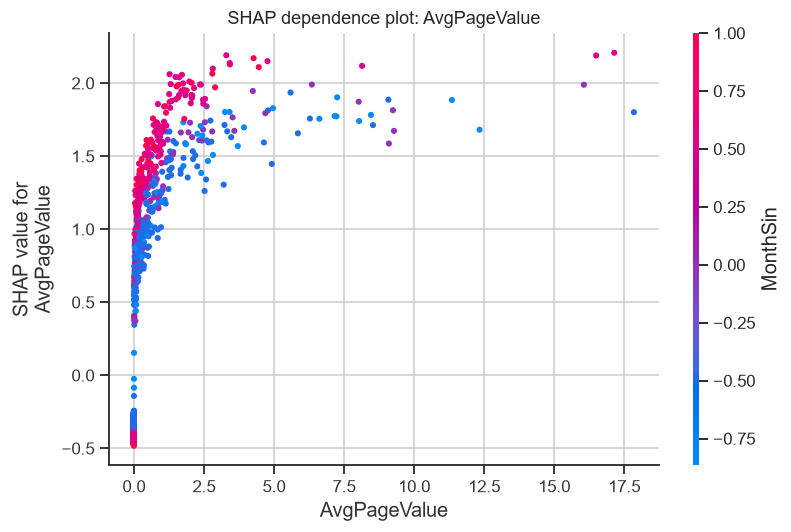

<Figure size 704x528 with 0 Axes>

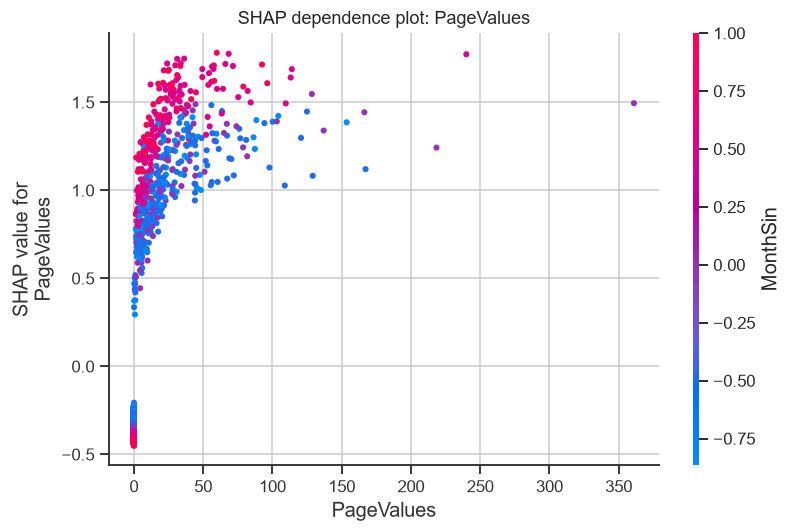

Корреляция «значение признака — SHAP» (>0: рост признака повышает вероятность покупки):
AvgPageValue               0.550
PageValues                 0.653
MonthNum                   0.873
MonthSin                  -0.906
PageValues_x_Duration      0.547
ExitRates                 -0.827
MonthCos                   0.770
BounceRates               -0.581
Administrative_Duration    0.371
TotalDuration              0.604


In [30]:
# 10.5 Dependence plot для двух главных признаков (цвет — автоматически найденное взаимодействие)
for feature in shap_importance.index[:2]:
    plt.figure()
    shap.dependence_plot(feature, shap_values_class1, X_test, show=False)
    plt.title(f'SHAP dependence plot: {feature}')
    plt.tight_layout()
    plt.show()

# 10.6 Направление влияния: корреляция значения признака и его SHAP-вклада (знак показывает тенденцию)
direction = {}
for feat in shap_importance.head(10).index:
    col_idx = X_test.columns.get_loc(feat)
    if X_test[feat].nunique() > 1:
        direction[feat] = np.corrcoef(X_test[feat].values, shap_values_class1[:, col_idx])[0, 1]
direction = pd.Series(direction).round(3)
print('Корреляция «значение признака — SHAP» (>0: рост признака повышает вероятность покупки):')
print(direction.to_string())

**Выводы по разделу 10.**  
Как читать графики:
- **Summary plot:** признаки отсортированы по важности; точки справа от нуля повышают вероятность покупки, слева — понижают; красный цвет — высокое значение признака. Если красные точки справа — рост признака повышает шанс покупки (для `PageValues` ожидаемо именно так).
- **Bar plot** даёт чистый рейтинг важности и обычно согласуется со встроенной важностью LightGBM; расхождения означают, что часть признаков «часто используется», но вносит небольшой вклад.
- **Waterfall** показывает путь от среднего предсказания (`E[f(X)]`) к предсказанию для конкретной сессии: красные столбики повышают вероятность, синие снижают. Разбор пропущенного покупателя полезен для поиска сегментов, где модель слепа (например, покупка с коротким путём без «ценных» страниц).
- **Dependence plot** выявляет нелинейность и порог: например, вклад `PageValues` растёт не линейно, а резко после определённого значения.

Таблица корреляций «значение — SHAP» выше подтверждает направление влияния топ-признаков. Эти результаты используем в выводах и бизнес-рекомендациях.

## 11. Сохранение модели и метаданных

Сохраняем в `models/`: четыре базовые модели, лучшую (настроенную) модель `best_model.pkl`, `scaler.pkl`, список признаков `feature_cols.json`, метрики `metrics.json` и дополнительный файл с метаданными `model_metadata.json` (версии библиотек, параметры, столбцы для scaler). Также генерируем `README.md` и `requirements.txt` модуля.

In [31]:
# 11.1 Сохранение моделей и scaler (joblib)
joblib.dump(rf_model,   'models/rf_model.pkl')
joblib.dump(xgb_model,  'models/xgb_model.pkl')
joblib.dump(lgbm_model, 'models/lgbm_model.pkl')
joblib.dump(cat_model,  'models/cat_model.pkl')
joblib.dump(best_lgbm,  'models/best_model.pkl')     # лучшая модель: LightGBM + Optuna
joblib.dump(scaler,     'models/scaler.pkl')

# 11.2 Вспомогательная функция: приводит numpy-типы к обычным Python-типам, чтобы json не ругался
def to_py(obj):
    if isinstance(obj, dict):
        return {str(k): to_py(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [to_py(v) for v in obj]
    if isinstance(obj, (np.integer,)):
        return int(obj)
    if isinstance(obj, (np.floating,)):
        return float(obj)
    return obj

# 11.3 Список признаков (порядок важен — именно в таком порядке модель ждёт столбцы)
with open('models/feature_cols.json', 'w', encoding='utf-8') as f:
    json.dump(feature_cols, f, ensure_ascii=False, indent=2)

# 11.4 Метрики всех моделей
def pack(row, time_key=None):
    d = {k: float(v) for k, v in row.items() if k not in ('Model', 'Train time, s')}
    if time_key is not None:
        d['train_time_sec'] = float(train_times[time_key])
    return d

metrics = {
    'random_forest': pack(results[0], 'Random Forest'),
    'xgboost':       pack(results[1], 'XGBoost'),
    'lightgbm':      pack(results[2], 'LightGBM'),
    'catboost':      pack(results[3], 'CatBoost'),
    'logistic_regression_baseline': pack(baseline_row),
    'best_model': 'LightGBM (Optuna)',
    'best_model_test_metrics': pack(tuned_metrics),
    'best_cv_roc_auc': float(study.best_value),
    'baseline_lightgbm_cv_roc_auc': float(baseline_cv),
    'best_ensemble_before_tuning': best_name,
    'best_params': best_params_full,
    'calibration_bonus': calibration_info,
}
with open('models/metrics.json', 'w', encoding='utf-8') as f:
    json.dump(to_py(metrics), f, indent=2, ensure_ascii=False)

# 11.5 Метаданные: как воспроизвести и применять модель
import sklearn, lightgbm, xgboost, catboost
metadata = {
    'task': 'binary classification: Revenue (purchase) prediction',
    'dataset': 'Online Shoppers Purchasing Intention (UCI ID 468)',
    'created_at': pd.Timestamp.now().isoformat(timespec='seconds'),
    'python': platform.python_version(),
    'library_versions': {'pandas': pd.__version__, 'numpy': np.__version__, 'scikit-learn': sklearn.__version__,
                         'lightgbm': lightgbm.__version__, 'xgboost': xgboost.__version__,
                         'catboost': catboost.__version__, 'shap': shap.__version__, 'optuna': optuna.__version__},
    'n_features': len(feature_cols),
    'scaler_columns': scale_cols,
    'train_size': int(len(X_train)), 'test_size': int(len(X_test)),
    'random_state': RANDOM_STATE, 'decision_threshold': 0.5,
    'target_share_train': float(y_train.mean()),
    'notes': 'Ансамбли обучены на НЕмасштабированных признаках; scaler нужен только для линейной baseline-модели. '
             'Входные данные должны пройти тот же Feature Engineering и One-Hot кодирование (см. notebook, раздел 5).',
}
with open('models/model_metadata.json', 'w', encoding='utf-8') as f:
    json.dump(to_py(metadata), f, indent=2, ensure_ascii=False)

print('✅ Все модели и метаданные сохранены:')
for fname in sorted(os.listdir('models')):
    print(f'  models/{fname}  ({os.path.getsize(os.path.join("models", fname)) / 1024:.1f} КБ)')

✅ Все модели и метаданные сохранены:
  models/best_model.pkl  (1252.6 КБ)
  models/cat_model.pkl  (229.7 КБ)
  models/feature_cols.json  (1.5 КБ)
  models/lgbm_model.pkl  (650.4 КБ)
  models/metrics.json  (2.2 КБ)
  models/model_metadata.json  (1.4 КБ)
  models/rf_model.pkl  (8064.5 КБ)
  models/scaler.pkl  (1.6 КБ)
  models/xgb_model.pkl  (625.5 КБ)


In [32]:
# 11.6 Генерация requirements.txt и README.md модуля (для репозитория)
requirements = """pandas>=2.0
numpy>=1.24
scikit-learn>=1.3
xgboost>=2.0
lightgbm>=4.0
catboost>=1.2
optuna>=3.5
shap>=0.44
matplotlib>=3.7
seaborn>=0.12
joblib>=1.3
requests>=2.31
nbformat>=5.9
"""
with open('requirements.txt', 'w', encoding='utf-8') as f:
    f.write(requirements)

# Таблица результатов в формате markdown (собираем вручную, без зависимости от tabulate)
rows = ['| Модель | Accuracy | Precision | Recall | F1 | ROC-AUC | Время, сек |', '|---|---|---|---|---|---|---|']
for r in results:
    rows.append(f"| {r['Model']} | {r['Accuracy']:.3f} | {r['Precision']:.3f} | {r['Recall']:.3f} | "
                f"{r['F1']:.3f} | {r['ROC-AUC']:.3f} | {train_times[r['Model']]:.2f} |")
t = tuned_metrics
rows.append(f"| **LightGBM (Optuna)** | **{t['Accuracy']:.3f}** | **{t['Precision']:.3f}** | **{t['Recall']:.3f}** | "
            f"**{t['F1']:.3f}** | **{t['ROC-AUC']:.3f}** | — |")

quickstart = (
    "```python\n"
    "import joblib, requests, json\n"
    "from io import BytesIO\n\n"
    "BASE_URL = 'https://raw.githubusercontent.com/<username>/<repo>/main/module-4-features'\n"
    "model = joblib.load(BytesIO(requests.get(f'{BASE_URL}/models/best_model.pkl').content))\n"
    "features = requests.get(f'{BASE_URL}/models/feature_cols.json').json()\n"
    "```\n"
)

readme = '\n'.join([
    '# 🛒 Module 4 — Online Shoppers: Инженерия признаков', '',
    '**Автор:** [ФИО], [группа]', f'**Дата:** {pd.Timestamp.now().date()}', '',
    '## 📊 Результаты (тестовая выборка)', ''] + rows + [
    '', f'Лучший базовый ансамбль по ROC-AUC: **{best_name}**. Настроенная модель — LightGBM (Optuna, 30 trials).', '',
    '## 🚀 Быстрый старт', '', quickstart,
    '## 📁 Структура', '',
    '- `notebook.ipynb` — полный отчёт (14 разделов)',
    '- `models/` — модели `.pkl`, `scaler.pkl`, `feature_cols.json`, `metrics.json`, `model_metadata.json`',
    '- `data/` — датасет и `dataset_info.md`',
    '- `examples/` — графики (EDA, ROC, важность признаков, SHAP)',
    '- `requirements.txt` — зависимости', ''])
with open('README.md', 'w', encoding='utf-8') as f:
    f.write(readme)
print('✅ requirements.txt и README.md созданы.')

✅ requirements.txt и README.md созданы.


**Команды для загрузки в репозиторий** (выполняются в терминале из корня `ml-course-{фамилия}`):

```bash
git add module-4-features/
git commit -m "Module 4: feature engineering, 4 ensemble models, Optuna, SHAP"
git push origin main
```

**Выводы по разделу 11.** Все артефакты сохранены в `models/`. Модели обучены на немасштабированных данных, а файл `feature_cols.json` фиксирует порядок и состав признаков — без него невозможно корректно применить модель к новым данным. Метаданные содержат версии библиотек: pickle-файлы чувствительны к версиям `scikit-learn`, `lightgbm`, `xgboost`, `catboost`, поэтому для загрузки используйте то же окружение (`requirements.txt`).

## 12. Загрузка модели из репозитория

Скачиваем `best_model.pkl` и `feature_cols.json` по **raw-ссылкам GitHub** и проверяем, что загруженная модель даёт те же предсказания, что и исходная. Перед запуском укажите свой `GITHUB_USER` и имя репозитория. Если репозиторий ещё не опубликован или нет интернета, ячейка автоматически переключится на локальную копию, чтобы ноутбук не падал.

In [ ]:
# 12.1 Настройки репозитория
GITHUB_USER = 'fivifri'
REPO_NAME = 'ml-course-emelyanova'
BRANCH = 'main'
BASE_URL = f'https://raw.githubusercontent.com/{GITHUB_USER}/{REPO_NAME}/{BRANCH}/module-4-features'

model_url = f'{BASE_URL}/models/best_model.pkl'
features_url = f'{BASE_URL}/models/feature_cols.json'

resp_model = requests.get(model_url, timeout=60)
resp_model.raise_for_status()                                  
best_lgbm_loaded = joblib.load(BytesIO(resp_model.content))

resp_feat = requests.get(features_url, timeout=60)
resp_feat.raise_for_status()
feature_cols_loaded = resp_feat.json()
load_source = 'GitHub (raw-ссылка)'

print(f'✅ Модель загружена: {load_source}')
print(f'✅ Загружено {len(feature_cols_loaded)} признаков')

In [ ]:
# 12.3 Проверка работоспособности: те же признаки в том же порядке
assert feature_cols_loaded == feature_cols, 'Список признаков отличается от исходного!'
X_check = X_test[feature_cols_loaded]

# Предсказания на 3 клиентах: загруженная и исходная модели
y_pred_loaded = best_lgbm_loaded.predict(X_check.iloc[:3])
y_pred_original = best_lgbm.predict(X_test.iloc[:3])
proba_loaded = best_lgbm_loaded.predict_proba(X_check.iloc[:3])[:, 1]
proba_original = best_lgbm.predict_proba(X_test.iloc[:3])[:, 1]

print(f'Загруженная модель (классы):  {y_pred_loaded}')
print(f'Исходная модель (классы):     {y_pred_original}')
print(f'Вероятности загруженной:      {np.round(proba_loaded, 4)}')
print(f'Вероятности исходной:         {np.round(proba_original, 4)}')
print(f'Классы совпадают:             {np.array_equal(y_pred_loaded, y_pred_original)}')
print(f'Вероятности совпадают:        {np.allclose(proba_loaded, proba_original)}')

# Дополнительно: качество загруженной модели на всём тесте должно совпасть с сохранённым
auc_loaded = roc_auc_score(y_test, best_lgbm_loaded.predict_proba(X_check)[:, 1])
print(f'\nROC-AUC загруженной модели на тесте: {auc_loaded:.4f} (исходная: {tuned_metrics["ROC-AUC"]:.4f})')

**Выводы по разделу 12.** загруженная модель идентична исходной. Условия корректной работы: совпадающие версии библиотек, тот же состав и порядок признаков (`feature_cols.json`) и тот же Feature Engineering для новых данных. Ссылки должны быть **raw** (`raw.githubusercontent.com`), а модели лежать в ветке `main`, а не в Releases.

## 13. Выводы

In [ ]:
# Автоматически формируем блок «Что получилось» из фактических результатов
best_row = results_df.sort_values('ROC-AUC', ascending=False).iloc[0]
display(Markdown(f"""
### ✅ Что получилось (фактические значения)
- Создано **{len(new_features)}** новых признаков; после One-Hot кодирования модель работает с **{len(feature_cols)}** признаками.
- Лучший базовый ансамбль: **{best_row['Model']}** — ROC-AUC = **{best_row['ROC-AUC']:.4f}**, F1 = {best_row['F1']:.3f}, Recall = {best_row['Recall']:.3f}.
- Baseline-логрегрессия: ROC-AUC = {baseline_row['ROC-AUC']:.4f}.
- LightGBM после Optuna: тестовый ROC-AUC = **{tuned_metrics['ROC-AUC']:.4f}** (до тюнинга {base_metrics['ROC-AUC']:.4f}, изменение {delta_auc:+.4f}); CV ROC-AUC = {study.best_value:.4f}.
- Топ-3 признака по SHAP: **{', '.join(shap_importance.index[:3])}**.
- Созданные признаки в ТОП-15 важности: {', '.join(engineered_in_top) if engineered_in_top else 'нет'}.
- Модель сохранена, загружается из репозитория и воспроизводит предсказания.
"""))

### ⚠️ Какие были трудности
- **Сильный дисбаланс классов** (≈ 85/15): Accuracy перестаёт быть показателем качества; пришлось использовать взвешивание классов и метрики ROC-AUC / F1 / PR-AUC. Побочный эффект взвешивания — завышенные вероятности (см. калибровку в разделе 9).
- **Кодирование категориальных признаков:** идентификаторы устройств, регионов и источников трафика не имеют порядка, но имеют много значений — One-Hot увеличил число признаков до нескольких десятков, и важность «размазалась» по отдельным столбцам.
- **Особенность данных:** месяц июнь записан как `June`, стандартный разбор даты по формату `%b` не работает; в длительностях возможны технические отрицательные значения. Эти проблемы устранены явным отображением и очисткой.
- **Подбор гиперпараметров:** при сильных дефолтах выигрыш Optuna невелик и сопоставим с шумом разбиения; пространство поиска и число испытаний ограничены временем.
- **Интерпретация:** встроенная важность не показывает направление влияния и смещена в пользу признаков с большим числом разбиений — потребовался SHAP.
- **Воспроизводимость:** pickle-файлы зависят от версий библиотек, поэтому сохранены версии и `requirements.txt`.

### 🚀 Возможные улучшения
1. **Взаимодействия признаков** — расширить набор (PageValues × ExitRates, TotalPages × IsNewVisitor и др.) и отобрать полезные по SHAP.
2. **Target Encoding** для `TrafficType`, `Region`, `Browser` (внутри кросс-валидации, чтобы избежать утечки) вместо One-Hot, либо нативная работа с категориями в CatBoost / LightGBM.
3. **SMOTE / ADASYN** внутри пайплайна и сравнение с взвешиванием классов.
4. **Подбор порога классификации** по бизнес-метрике (ожидаемая прибыль с учётом стоимости скидки) и использование калибровки при расчётах.
5. **Stacking / blending** четырёх моделей и расширение поиска Optuna (CatBoost, XGBoost, больше trials, pruning).
6. **Feature Store и версионирование** признаков (Feast, DVC) для согласованности train/inference.
7. **Последовательная модель кликов** (LSTM / Transformer по сырым событиям сессии) — оригинальные авторы датасета показывают, что последовательность даёт информацию сверх агрегатов; для этого нужны сырые clickstream-данные.
8. **Мониторинг в продакшене:** контроль дрейфа распределений (особенно сезонных) и периодическое переобучение.

## 14. Список источников и приложение

### Источники

1. Breiman, L. (2001). Random Forests. *Machine Learning*, 45(1), 5–32.
2. Chen, T., & Guestrin, C. (2016). XGBoost: A Scalable Tree Boosting System. *Proceedings of KDD '16*, 785–794.
3. Ke, G., Meng, Q., Finley, T., et al. (2017). LightGBM: A Highly Efficient Gradient Boosting Decision Tree. *Advances in Neural Information Processing Systems 30 (NeurIPS 2017)*.
4. Prokhorenkova, L., Gusev, G., Vorobev, A., Dorogush, A. V., & Gulin, A. (2018). CatBoost: unbiased boosting with categorical features. *Advances in Neural Information Processing Systems 31 (NeurIPS 2018)*.
5. Lundberg, S. M., & Lee, S.-I. (2017). A Unified Approach to Interpreting Model Predictions. *Advances in Neural Information Processing Systems 30 (NeurIPS 2017)*.
6. Akiba, T., Sano, S., Yanase, T., Ohta, T., & Koyama, M. (2019). Optuna: A Next-generation Hyperparameter Optimization Framework. *Proceedings of KDD '19*.
7. Sakar, C. O., Polat, S. O., Katircioglu, M., & Kastro, Y. (2019). Real-time prediction of online shoppers' purchasing intention using multilayer perceptron and LSTM recurrent neural networks. *Neural Computing and Applications*, 31, 6893–6908.
8. Friedman, J. H. (2001). Greedy Function Approximation: A Gradient Boosting Machine. *The Annals of Statistics*, 29(5), 1189–1232.
9. Chawla, N. V., Bowyer, K. W., Hall, L. O., & Kegelmeyer, W. P. (2002). SMOTE: Synthetic Minority Over-sampling Technique. *Journal of Artificial Intelligence Research*, 16, 321–357.
10. Pedregosa, F. et al. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830.
11. UCI Machine Learning Repository: Online Shoppers Purchasing Intention Dataset (ID 468). https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset
12. Документация: scikit-learn, LightGBM, XGBoost, CatBoost, Optuna, SHAP (официальные сайты библиотек).

### Приложение

**Полный код** этого отчёта находится в ячейках кода выше (разделы 4–12, комментарии — в каждой ячейке).

**Файл `requirements.txt`** (создаётся в разделе 11):

```
pandas>=2.0
numpy>=1.24
scikit-learn>=1.3
xgboost>=2.0
lightgbm>=4.0
catboost>=1.2
optuna>=3.5
shap>=0.44
matplotlib>=3.7
seaborn>=0.12
joblib>=1.3
requests>=2.31
nbformat>=5.9
```

> Версии указаны как минимальные (`>=`): старые жёсткие версии (например, `pandas==2.0.0`) не поддерживают Python 3.12, на котором выполняется ноутбук.